# Fine-Tuning Model XAUUSD — Update Mengikuti Pasar 2026
Notebook ini **TIDAK melatih model dari nol**. Notebook ini mengambil model BUY/SELL
yang sudah kamu latih sebelumnya (`buy_model.pkl`, `sell_model.pkl`, `scaler.pkl`) dan
melanjutkan training (fine-tuning) memakai data candle **terbaru sejak awal 2026** saja,
supaya model lebih mengikuti rezim pasar terkini tanpa harus mengulang training multi-tahun
dari awal.

## Yang perlu kamu siapkan sebelum run
Taruh 3 file berikut di folder yang sama dengan notebook ini (ubah `MODEL_DIR` di bawah
kalau lokasinya berbeda):
- `buy_model.pkl`
- `sell_model.pkl`
- `scaler.pkl`

Ketiganya adalah output dari notebook trainingmu yang lama
(`prediksi_precision70_binary_3_multiframe_...`).

## Apa yang notebook ini lakukan
1. Fetch candle M5/M15/M30/H1 dari Dukascopy, mulai **beberapa bulan sebelum 2026**
   (buffer, supaya indikator seperti EMA200/rolling(200) sudah "matang" sebelum
   1 Jan 2026 — bukan berarti datanya dipakai untuk training).
2. Feature engineering & merge multi-timeframe — **identik** dengan notebook aslimu
   (kolom fitur, urutan, dan rumus semuanya sama supaya cocok dengan model lama).
3. Buat label triple-barrier dengan `WINDOW_SIZE`, `HORIZON`, `PT_SL` **yang sama** dengan
   training aslimu.
4. Filter dataset supaya **hanya sampel dari 1 Jan 2026 ke atas** yang dipakai untuk
   fine-tuning (data sebelum itu cuma dipakai sebagai warm-up indikator, bukan untuk
   training).
5. Pakai scaler lama (**tidak di-fit ulang**) supaya skala fitur tetap konsisten dengan
   bobot model yang sudah dilatih.
6. Load `buy_model.pkl` / `sell_model.pkl`, lanjutkan training dengan **learning rate
   kecil** dan **epoch sedikit** (fine-tuning, bukan training ulang).
7. Bandingkan metrik (AUC/precision) sebelum vs sesudah fine-tuning, lalu simpan model
   baru sebagai `buy_model_finetuned.pkl` / `sell_model_finetuned.pkl` (file asli tidak
   ditimpa, supaya kamu bisa membandingkan / rollback).

> **Catatan penting:** data 6 bulan (Jan–Jul 2026) jauh lebih sedikit dan lebih sempit
> variasi rezimnya dibanding data multi-tahun training asli. Fine-tuning dengan LR kecil
> + epoch sedikit dimaksudkan supaya model **menyesuaikan** ke rezim terkini tanpa
> "lupa" (catastrophic forgetting) pola-pola umum yang sudah dipelajari dari data lama.
> Selalu bandingkan hasil val AUC/precision sebelum-sesudah sebelum dipakai live.

In [1]:
import os

# Ubah kalau file model lama kamu ada di folder lain
MODEL_DIR = "."

PATH_BUY_MODEL  = os.path.join(MODEL_DIR, "buy_model.pkl")
PATH_SELL_MODEL = os.path.join(MODEL_DIR, "sell_model.pkl")
PATH_SCALER     = os.path.join(MODEL_DIR, "scaler.pkl")

for p in (PATH_BUY_MODEL, PATH_SELL_MODEL, PATH_SCALER):
    status = "OK" if os.path.exists(p) else "TIDAK DITEMUKAN"
    print(f"{status:16s} -> {p}")

missing = [p for p in (PATH_BUY_MODEL, PATH_SELL_MODEL, PATH_SCALER) if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(
        "File model berikut belum ada, upload dulu sebelum lanjut:\n" +
        "\n".join(missing)
    )


OK               -> .\buy_model.pkl
OK               -> .\sell_model.pkl
OK               -> .\scaler.pkl


In [2]:
import torch
import dukascopy_python
from dukascopy_python.instruments import INSTRUMENT_FX_METALS_XAU_USD
import datetime
import pandas as pd
import numpy as np
import gc

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# SPEEDUP: cuDNN akan benchmark & pilih algoritma conv tercepat untuk ukuran
# input yang tetap (window/batch kita selalu sama tiap step) -- cuma perlu
# di-set sekali di awal notebook, sebelum training mulai. Tidak mengubah
# hasil training sama sekali, cuma mempercepat pemilihan kernel conv di GPU.
if device == "cuda":
    torch.backends.cudnn.benchmark = True

# ================= KONFIGURASI DUKASCOPY =================
# Tidak perlu API key / akun sama sekali — Dukascopy menyediakan history
# gratis untuk publik (data sejak awal 2000-an untuk XAU/USD).
INSTRUMENT = INSTRUMENT_FX_METALS_XAU_USD   # "XAU/USD" (Gold vs USD), setara XAUUSD di MT5
OFFER_SIDE = dukascopy_python.OFFER_SIDE_BID


Device: cuda


In [3]:
# Dukascopy tidak butuh initialize/login seperti MT5 — cukup tes fetch kecil untuk memastikan koneksi jalan
_test = dukascopy_python.fetch(
    INSTRUMENT,
    dukascopy_python.INTERVAL_HOUR_1,
    OFFER_SIDE,
    datetime.datetime.utcnow() - datetime.timedelta(days=3),
    datetime.datetime.utcnow(),
)

if _test is not None and len(_test) > 0:
    print("Berhasil terhubung ke Dukascopy (tidak perlu API key / akun).")
    print(_test.tail(3))
else:
    print("Gagal mengambil data test dari Dukascopy — cek koneksi internet Anda.")


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18584\1564275067.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  datetime.datetime.utcnow() - datetime.timedelta(days=3),
C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18584\1564275067.py:7: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  datetime.datetime.utcnow(),
INFO:DUKASCRIPT:current timestamp :2026-07-03T23:00:00


Berhasil terhubung ke Dukascopy (tidak perlu API key / akun).
                               open      high       low     close   volume
timestamp                                                                 
2026-07-03 14:00:00+00:00  4164.305  4170.965  4155.085  4169.485  1.32987
2026-07-03 15:00:00+00:00  4169.515  4174.265  4164.265  4164.545  0.96954
2026-07-03 16:00:00+00:00  4164.565  4176.055  4162.535  4175.245  0.67476


## 1. Feature Engineering

(Identik dengan notebook training asli — kolom & rumus fitur tidak boleh beda supaya cocok dengan model lama.)

In [4]:
from ta.volatility import BollingerBands
def add_ema(df):
    df["ema20"]  = df["close"].ewm(span=20).mean()
    df["ema50"]  = df["close"].ewm(span=50).mean()
    df["ema200"] = df["close"].ewm(span=200).mean()
    df["ema20_dist"]  = (df["close"] - df["ema20"])  / df["ema20"]
    df["ema50_dist"]  = (df["close"] - df["ema50"])  / df["ema50"]
    df["ema200_dist"] = (df["close"] - df["ema200"]) / df["ema200"]
    return df

def add_bb(df):

    bb = BollingerBands(df["close"], window=20)

    df["bb_upper"] = bb.bollinger_hband()
    df["bb_lower"] = bb.bollinger_lband()
    df["bb_middle"] = bb.bollinger_mavg()

    df["bb_position"] = (
        (df["close"]-df["bb_lower"]) /
        (df["bb_upper"]-df["bb_lower"]+1e-8)
    )

    return df

def add_macd(df):
    ema12 = df["close"].ewm(span=12).mean()
    ema26 = df["close"].ewm(span=26).mean()
    df["macd"]        = (ema12 - ema26) / df["close"]
    df["macd_signal"] = df["macd"].ewm(span=9).mean()
    return df

def add_rsi(df, period=14):
    # Hitung selisih close, pertahankan indeks asli df
    delta = df["close"].diff()
    
    # Gunakan np.where tetapi langsung bungkus dengan Series bernilai indeks sama dengan df
    gain = pd.Series(np.where(delta > 0, delta, 0.0), index=df.index)
    loss = pd.Series(np.where(delta < 0, -delta, 0.0), index=df.index)
    
    # Menggunakan Wilder's Exponential Moving Average (Sama seperti MT5/TradingView)
    # alpha=1/period adalah standar kalkulasi RSI Wilder
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    rs = avg_gain / (avg_loss + 1e-9)
    df["rsi"] = 100 - (100 / (1 + rs))
    
    # Opsional: langsung normalisasi ke skala -1 s.d 1 agar Conv-GRU kamu lebih stabil
    df["rsi_norm"] = (df["rsi"] - 50) / 50
    
    return df

def add_atr(df, period=14):
    hl  = df["high"] - df["low"]
    hc  = np.abs(df["high"] - df["close"].shift())
    lc  = np.abs(df["low"]  - df["close"].shift())
    tr  = np.maximum(hl, np.maximum(hc, lc))
    df["atr"] = pd.Series(tr).rolling(period).mean()
    return df

def calculate_volume_profile_rolling(df, window=60, n_bins=10):
    """
    Menghitung jarak harga saat ini ke Point of Control (POC) berdasarkan Rolling Window.
    """
    poc_distances = np.zeros(len(df))
    
    # Konversi ke numpy array untuk kecepatan komputasi
    closes = df['close'].values
    volumes = df['tick_volume'].values
    
    for i in range(window, len(df)):
        # Ambil window historis
        window_closes = closes[i-window:i]
        window_volumes = volumes[i-window:i]
        
        # Buat Price Bins berdasarkan harga tertinggi dan terendah di window tersebut
        min_p, max_p = window_closes.min(), window_closes.max()
        if max_p == min_p:
            poc_distances[i] = 0
            continue
            
        bins = np.linspace(min_p, max_p, n_bins + 1)
        
        # Hitung volume digital (horizontal volume) per bin
        # Mencari tahu setiap close masuk ke bin mana
        bin_indices = np.digitize(window_closes, bins) - 1
        bin_indices = np.clip(bin_indices, 0, n_bins - 1)
        
        bin_volumes = np.zeros(n_bins)
        for idx, vol in zip(bin_indices, window_volumes):
            bin_volumes[idx] += vol
            
        # Temukan bin dengan volume terbesar (Point of Control / POC)
        poc_bin_idx = np.argmax(bin_volumes)
        # Ambil nilai tengah harga dari bin POC tersebut
        poc_price = (bins[poc_bin_idx] + bins[poc_bin_idx + 1]) / 2
        
        # Hitung jarak relatif % harga close saat ini ke POC
        poc_distances[i] = (closes[i] - poc_price) / poc_price
        
    return poc_distances

def calculate_price_density_rolling(df, window=120, tolerance_atr_mult=0.5):
    """
    Menghitung seberapa sering area harga saat ini dijadikan titik pantulan (High/Low) di masa lalu.
    """
    density_counts = np.zeros(len(df))
    
    closes = df['close'].values
    highs = df['high'].values
    lows = df['low'].values
    atrs = df['atr'].values  # Pastikan kamu sudah menghitung kolom 'atr' sebelumnya
    
    for i in range(window, len(df)):
        current_close = closes[i]
        current_atr = atrs[i]
        
        # Tentukan batas toleransi area S/R berdasarkan volatilitas (ATR)
        # Supaya dinamis mengikuti kondisi market XAUUSD
        buffer = current_atr * tolerance_atr_mult
        
        # Ambil data High dan Low historis dalam window
        window_highs = highs[i-window:i]
        window_lows = lows[i-window:i]
        
        # Hitung berapa banyak High/Low masa lalu yang nempel di harga Close saat ini
        high_hits = np.sum((window_highs >= current_close - buffer) & (window_highs <= current_close + buffer))
        low_hits = np.sum((window_lows >= current_close - buffer) & (window_lows <= current_close + buffer))
        
        # Total interaksi harga (Price Density)
        density_counts[i] = high_hits + low_hits
        
    # Normalisasi agar skalanya sehat masuk ke model (Z-Score rolling sederhana)
    # Atau bisa dibagi dengan 'window' agar menghasilkan rasio 0 sampai 1
    return density_counts / (window * 2)

def calculate_daily_anchors(df_intraday):
    """
    Menghitung High, Low, PP, R1, dan S1 dari hari sebelumnya (Yesterday).
    Asumsi: df_intraday memiliki DatetimeIndex.
    """
    # 1. Resample data intraday ke skala Harian (Daily)
    daily = df_intraday['close'].resample('D').ohlc()
    
    # Masukkan data High dan Low harian murni
    daily['high'] = df_intraday['high'].resample('D').max()
    daily['low'] = df_intraday['low'].resample('D').min()
    
    # Drop hari yang tidak ada transaksi (misal akhir pekan)
    daily = daily.dropna()
    
    # 2. Geser data (SHIFT 1) agar hari ini menggunakan data "HARI KEMARIN"
    # Ini krusial agar model tidak mencontek data hari ini!
    daily['prev_high'] = daily['high'].shift(1)
    daily['prev_low'] = daily['low'].shift(1)
    daily['prev_close'] = daily['close'].shift(1)
    
    # 3. Hitung Rumus Pivot Point Standar berdasarkan data kemarin
    daily['PP'] = (daily['prev_high'] + daily['prev_low'] + daily['prev_close']) / 3
    daily['R1'] = (2 * daily['PP']) - daily['prev_low']
    daily['S1'] = (2 * daily['PP']) - daily['prev_high']
    
    # Kita hanya butuh kolom jangkar ini saja
    anchor_columns = ['prev_high', 'prev_low', 'PP', 'R1', 'S1']
    return daily[anchor_columns]

def generate_anchor_distance_features(df):
    """
    Menggabungkan jangkar harian ke data intraday dan menghitung jarak relatif %.
    """
    # FIX KRITIS: df.index sebelumnya RangeIndex (0,1,2,...) hasil pd.concat,
    # BUKAN timestamp asli. `pd.to_datetime(df.index)` lama mengubah angka baris
    # jadi nanodetik sejak epoch 1970-01-01 — semua anchor harian (PP/R1/S1) dan
    # fitur turunannya jadi dihitung dari "tanggal" yang salah total.
    # Sekarang index dibangun dari kolom 'time' (unix seconds) yang benar.
    df = df.copy()
    df.index = pd.to_datetime(df['time'], unit='s')

    # Buat kolom pembantu berupa 'tanggal' saja untuk merge
    df['date_key'] = df.index.date
    
    # Hitung jangkar harian
    daily_anchors = calculate_daily_anchors(df)
    daily_anchors.index = daily_anchors.index.date # Ubah index menjadi tanggal saja
    
    # Gabungkan (Merge) data intraday dengan data jangkar harian
    df = df.merge(daily_anchors, left_on='date_key', right_index=True, how='left')
    
    # Isu hari Senin: Karena shift(1) hari Minggu kosong, kita forward fill (ffill) jika ada bolong
    df[['prev_high', 'prev_low', 'PP', 'R1', 'S1']] = df[['prev_high', 'prev_low', 'PP', 'R1', 'S1']].ffill()
    
    # 4. HITUNG JARAK RELATIF (%)
    # Rumus: (Harga Sekarang - Harga Jangkar) / Harga Jangkar
    df['prev_day_high_dist'] = (df['close'] - df['prev_high']) / df['prev_high']
    df['prev_day_low_dist']  = (df['close'] - df['prev_low']) / df['prev_low']
    
    df['pivot_point_dist']   = (df['close'] - df['PP']) / df['PP']
    df['r1_dist']            = (df['close'] - df['R1']) / df['R1']
    df['s1_dist']            = (df['close'] - df['S1']) / df['S1']
    
    # Hapus kolom temporary agar dataset bersih kembali
    df = df.drop(columns=['date_key', 'prev_high', 'prev_low', 'PP', 'R1', 'S1'])
    
    # Isi data kosong di baris-baris awal dengan 0
    return df.fillna(0)

def calculate_volume_zscore(df, window=20):
    """
    Menghitung seberapa ekstrem volume saat ini dibanding rata-rata historisnya.
    """
    # 1. Hitung rata-rata rolling (Mean) dari volume
    roll_mean = df['tick_volume'].rolling(window=window).mean()
    
    # 2. Hitung standar deviasi rolling (Std Dev) dari volume
    roll_std = df['tick_volume'].rolling(window=window).std()
    
    # 3. Hitung Z-Score (tambahkan epsilon 1e-8 untuk menghindari pembagian dengan nol)
    volume_zscore = (df['tick_volume'] - roll_mean) / (roll_std + 1e-8)
    
    # Isi nilai NaN di awal window dengan 0
    return volume_zscore.fillna(0)

def calculate_atr_zscore(df, window=20):
    """
    Menghitung ekspansi atau kompresi volatilitas berdasarkan Z-Score dari ATR.
    Pastikan kolom 'atr' sudah ada di DataFrame kamu.
    """
    # 1. Hitung rata-rata rolling dari ATR
    roll_mean_atr = df['atr'].rolling(window=window).mean()
    
    # 2. Hitung standar deviasi rolling dari ATR
    roll_std_atr = df['atr'].rolling(window=window).std()
    
    # 3. Hitung Z-Score untuk mendeteksi spread expansion
    atr_zscore = (df['atr'] - roll_mean_atr) / (roll_std_atr + 1e-8)
    
    return atr_zscore.fillna(0)

def calculate_session_volume_zscore(df, window_days=20):
    """
    Menghitung Z-Score volume berdasarkan jam yang sama di hari-hari sebelumnya.
    Sangat kuat untuk menjinakkan bias waktu pada XAUUSD.
    """
    # Pastikan index berupa datetime
    df['hour_group'] = df.index.hour
    
    # Hitung rata-rata dan std dev per jam menggunakan transform rolling harian
    # Catatan: Asumsi data intraday lengkap. Pendekatan praktis:
    roll_mean = df.groupby('hour_group')['tick_volume'].transform(lambda x: x.rolling(window=window_days, min_periods=1).mean())
    roll_std = df.groupby('hour_group')['tick_volume'].transform(lambda x: x.rolling(window=window_days, min_periods=1).std())
    
    session_zscore = (df['tick_volume'] - roll_mean) / (roll_std + 1e-8)
    
    df = df.drop(columns=['hour_group'])
    return session_zscore.fillna(0)


def create_features(df):
    import numpy as np
    import pandas as pd

    # Returns
    df["return"] = df["close"].pct_change()
    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_2"]  = df["close"].pct_change(2)
    df["ret_3"]  = df["close"].pct_change(3)
    df["ret_6"]  = df["close"].pct_change(6)
    df["ret_12"] = df["close"].pct_change(12)
    df["ret_24"] = df["close"].pct_change(24)

    df = add_rsi(df)
    df = add_atr(df)
    df = add_ema(df)
    df = add_bb(df)
    df = add_macd(df)

    # Volatility
    df["volatility"] = df["return"].rolling(20).std()

    # Candle pattern (normalized)
    df["body"]       = (df["close"] - df["open"]) / df["close"]
    df["upper_wick"] = (df["high"] - np.maximum(df["open"], df["close"])) / df["close"]
    df["lower_wick"] = (np.minimum(df["open"], df["close"]) - df["low"]) / df["close"]

    # Time encoding & Day encoding
    datetime_col = pd.to_datetime(df["time"], unit="s")
    hour = datetime_col.dt.hour
    day_of_week = datetime_col.dt.dayofweek # 0=Senin, 6=Minggu

    # 1. Sesi Asia (06:00 - 14:00)
    df["sesi_asia"] = ((hour >= 6) & (hour <= 14)).astype(int)

    # 2. Sesi Eropa/London (14:00 - 22:00)
    df["sesi_eropa"] = ((hour >= 14) & (hour <= 22)).astype(int)

    # 3. Sesi Amerika / NY (19:00 - 03:00) -> Menggunakan OR (|) karena menyeberang tengah malam
    df["sesi_amerika"] = ((hour >= 19) | (hour <= 3)).astype(int)

    # 4. Sesi Golden / Overlap London-NY (19:00 - 22:00) -> Sangat penting untuk XAUUSD
    df["sesi_golden"] = ((hour >= 19) & (hour <= 22)).astype(int)
    
    # Sine/Cosine Encoding untuk Jam (Siklus 24 Jam)
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    # Sine/Cosine Encoding untuk Hari (Siklus 7 Hari - Sangat penting untuk anomali Senin/Jumat)
    df["day_sin"] = np.sin(2 * np.pi * day_of_week / 7)
    df["day_cos"] = np.cos(2 * np.pi * day_of_week / 7)

    # Momentum
    df["momentum_3"] = (df["close"] - df["close"].shift(3)) / df["close"]
    df["momentum_6"] = (df["close"] - df["close"].shift(6)) / df["close"]

    # Volume (hanya ratio — hapus vol_ma absolut)
    df["vol_ma"]    = df["tick_volume"].rolling(10).mean()
    df["vol_ratio"] = df["tick_volume"] / (df["vol_ma"] + 1e-9)

    # Bar strength
    df["bar_strength"] = np.abs(df["close"] - df["open"]) / (df["high"] - df["low"] + 1e-8)

    # Garman-Klass Volatility
    inside_sqrt = 0.5 * (np.log(df["high"] / df["low"])) ** 2 - (
        2 * np.log(2) - 1) * (np.log(df["close"] / df["open"])) ** 2
    df["vol_gk"] = np.sqrt(np.clip(inside_sqrt, 0, None))

    # Vol Z-Score (lookback 96)
    vol_m = df["vol_gk"].rolling(window=96).mean()
    vol_s = df["vol_gk"].rolling(window=96).std()
    df["vol_zscore"] = (df["vol_gk"] - vol_m) / (vol_s + 1e-8)

    # NATR = ATR (sudah / close di add_atr)
    df["natr"] = df["atr"] / df["close"]

    # Streak
    is_bull = (df["close"] > df["open"]).astype(int)
    is_bear = (df["close"] < df["open"]).astype(int)
    df["bull_streak"] = (is_bull.groupby((is_bull != is_bull.shift()).cumsum()).cumsum()) * is_bull
    df["bear_streak"] = (is_bear.groupby((is_bear != is_bear.shift()).cumsum()).cumsum()) * is_bear

    # Price position 96
    rolling_min = df["low"].rolling(window=96).min()
    rolling_max = df["high"].rolling(window=96).max()
    df["price_position_96"] = (df["close"] - rolling_min) / (rolling_max - rolling_min + 1e-8)

    # ── Divergence RSI ──
    df['rsi_slope_3']  = df['rsi'].diff(3)   # dipakai khusus untuk rsi_div
    df['price_slope']  = df['close'].pct_change(3)
    df['rsi_div']      = df['rsi_slope_3'] - df['price_slope'] * 100

    # ── Volume Confirmation ──
    df['vol_confirm'] = df['vol_ratio'] * df['body']

    # ── ATR Ratio (volatility regime) ──
    df['atr_ratio'] = df['atr'] / df['atr'].rolling(50).mean()

    # ── Candle efficiency ──
    df['efficiency'] = (df['close'] - df['open']).abs() / \
                       (df['high'] - df['low'] + 1e-8)

    # ── Higher timeframe trend (simulasi dari M5) ──
    df['trend_1h'] = np.sign(df['close'] - df['close'].ewm(span=12).mean())
    df['trend_4h'] = np.sign(df['close'] - df['close'].ewm(span=48).mean())

    df['poc_dist'] = calculate_volume_profile_rolling(df, window=60, n_bins=10)

    df['price_density'] = calculate_price_density_rolling(df, window=120, tolerance_atr_mult=0.5)

    df = generate_anchor_distance_features(df)

    df['volume_zscore'] = calculate_volume_zscore(df, window=20)

    df['atr_zscore'] = calculate_atr_zscore(df, window=20)

    df['volume_zscore_modular'] = calculate_session_volume_zscore(df, window_days=14)

    # ── Perbaikan Rumus FVG Khusus Scalping (Konsisten Menggunakan Huruf Kecil) ──
    
    # 1. Hitung ATR (Volatilitas Lokal) untuk menyaring noise
    df['tr'] = np.maximum(df['high'] - df['low'], 
                          np.maximum((df['high'] - df['close'].shift(1)).abs(), 
                                     (df['low'] - df['close'].shift(1)).abs()))
    df['atr_14'] = df['tr'].rolling(window=14).mean()

    df['tr_percentage'] = df['tr'] / df['close']
    df['atr_14_percentage'] = df['atr_14'] / df['close']

    # 2. Rumus Bullish FVG (Sudut Pandang Candle Tengah t)
    df['bullish_fvg_gap'] = df['low']        - df['high'].shift(2)   # c=t (current), a=t-2

    df['valid_scalp_fvg'] = ((df['bullish_fvg_gap'] > 0) & (df['bullish_fvg_gap'] > (df['atr_14'] * 0.5))).astype(int)
    
    # Koordinat absolut untuk Engine Eksekusi Bot
    df['entry_price'] = np.where(df['valid_scalp_fvg'] == 1, df['high'].shift(1), 0.0)
    df['bullish_sl'] = np.where(df['valid_scalp_fvg'] == 1, df['low'].shift(1), 0.0)

    # Fitur Jarak Relatif ke Bullish FVG (Untuk input model AI agar bebas kebocoran data)
    # Jika tidak ada FVG aktif, jarak diset ke 0
    df['bullish_fvg_dist'] = np.where(df['entry_price'] > 0, (df['close'] - df['entry_price']) / df['close'], 0.0)

    # 3. Rumus Bearish FVG (Sudut Pandang Candle Tengah t)
    df['bearish_fvg_gap'] = df['low'].shift(2) - df['high']          # a=t-2, c=t (current)
    df['valid_scalp_bearish_fvg'] = ((df['bearish_fvg_gap'] > 0) & (df['bearish_fvg_gap'] > (df['atr_14'] * 0.5))).astype(int)
    
    # Koordinat absolut untuk Engine Eksekusi Bot
    df['bearish_entry_price'] = np.where(df['valid_scalp_bearish_fvg'] == 1, df['low'].shift(1), 0.0)
    df['bearish_stop_loss'] = np.where(df['valid_scalp_bearish_fvg'] == 1, df['high'], 0.0)

    # Fitur Jarak Relatif ke Bearish FVG (Untuk input model AI agar bebas kebocoran data)
    df['bearish_fvg_dist'] = np.where(df['bearish_entry_price'] > 0, (df['close'] - df['bearish_entry_price']) / df['close'], 0.0)

    # EMA slope
    df["ema20_slope"] = df["ema20"].pct_change(3)
    df["ema50_slope"] = df["ema50"].pct_change(5)
    df["ema200_slope"] = df["ema200"].pct_change(10)

    # EMA spread
    df["ema20_50"] = (df["ema20"]-df["ema50"])/df["atr"]
    df["ema50_200"] = (df["ema50"]-df["ema200"])/df["atr"]

    # Trend persistence
    df["trend_strength"] = abs(df["ema20"]-df["ema50"])/(df["atr"]+1e-8)

    lookback = 48

    df["swing_high"] = df["high"].rolling(lookback).max()
    df["swing_low"]  = df["low"].rolling(lookback).min()

    df["dist_high"] = (df["swing_high"]-df["close"])/(df["atr"]+1e-8)
    df["dist_low"]  = (df["close"]-df["swing_low"])/(df["atr"]+1e-8)

    df["rv12"] = df["return"].rolling(12).std()
    df["rv24"] = df["return"].rolling(24).std()
    df["rv48"] = df["return"].rolling(48).std()

    df["vol_term"] = df["rv12"]/df["rv48"]

    roll = df.close.rolling(48)

    df["z_close"] = (
    df.close-roll.mean()
    )/(roll.std()+1e-8)

    df["trend_regime"] = (
    df["trend_strength"]>1.5
    ).astype(int)

    df["vol_regime"] = (
    df["atr_ratio"]>1.3
    ).astype(int)

    df["range_regime"] = (
    df["price_position_96"].between(0.3,0.7)
    ).astype(int)

    # dist_high/dist_low/trend_strength sudah dihitung di atas — duplikat dihapus
    df["rolling_trend"] = (
    df["ema20"]-df["ema50"]
    )/(df["atr"]+1e-8)

    df["return_acceleration"] = df["ret_3"] - df["ret_12"]

    # rsi_norm sudah dihitung di add_rsi() — duplikat dihapus
    df["rsi_slope"] = df["rsi"].diff()
    df["macd_hist"] = df["macd"]-df["macd_signal"]

    df["swing_range"] = (
        df["dist_high"] +
        df["dist_low"]
    )

    _prev_vol = df["tick_volume"].shift(1)
    df["volume_change"] = ((df["tick_volume"] - _prev_vol) / (_prev_vol.abs() + 1e-9)).clip(-20, 20)

    from ta.trend import ADXIndicator

    adx = ADXIndicator(
        high=df["high"],
        low=df["low"],
        close=df["close"],
        window=14
    )

    df["adx"] = adx.adx()
    df["+di"] = adx.adx_pos()
    df["-di"] = adx.adx_neg()

    df["adx"] = adx.adx()
    df["plus_di"] = adx.adx_pos()
    df["minus_di"] = adx.adx_neg()

    # =====================================================
    # Momentum Jangka Panjang
    # =====================================================
    
    df["ret_48"] = df["close"].pct_change(48)
    df["ret_96"] = df["close"].pct_change(96)
    
    # =====================================================
    # Trend Persistence
    # =====================================================
    
    df["trend_persistence"] = (
        (df["close"] > df["ema20"]).astype(int) +
        (df["ema20"] > df["ema50"]).astype(int) +
        (df["ema50"] > df["ema200"]).astype(int)
    )
    
    # =====================================================
    # Highest / Lowest Distance
    # =====================================================
    
    highest48 = df["high"].rolling(48).max()
    lowest48  = df["low"].rolling(48).min()
    
    df["dist_highest48"] = (highest48 - df["close"]) / df["atr"]
    df["dist_lowest48"]  = (df["close"] - lowest48) / df["atr"]
    
    # =====================================================
    # ATR Expansion
    # =====================================================
    
    df["atr_expand"] = df["atr"] / df["atr"].shift(10)
    
    # =====================================================
    # EMA Compression
    # =====================================================
    
    df["ema_compression"] = (
        (df["ema20"] - df["ema50"]).abs() /
        df["atr"]
    )
    
    # =====================================================
    # RSI Velocity
    # =====================================================
    
    df["rsi_velocity"] = df["rsi"].diff()
    df["rsi_acceleration"] = df["rsi_velocity"].diff()
    
    # =====================================================
    # Bollinger Width Change
    # =====================================================
    
    bb_width = (df["bb_upper"] - df["bb_lower"]) / df["bb_middle"]
    
    df["bb_width"] = bb_width
    df["bb_width_change"] = bb_width.pct_change()
    
    # =====================================================
    # Candle Strength
    # =====================================================
    
    range_ = (df["high"] - df["low"]).replace(0, np.nan)
    
    df["body_ratio"] = (
        (df["close"] - df["open"]).abs() / range_
    )
    
    df["bull_strength"] = (
        (df["close"] - df["low"]) / range_
    )
    
    df["bear_strength"] = (
        (df["high"] - df["close"]) / range_
    )
    
    # =====================================================
    # Volatility Rank
    # =====================================================
    
    df["volatility_rank"] = (
        df["volatility"]
        .rolling(200)
        .rank(pct=True)
    )
    
    # =====================================================
    # Breakout Strength
    # =====================================================
    
    highest20 = df["high"].rolling(20).max()
    lowest20  = df["low"].rolling(20).min()
    
    df["breakout_up"] = (
        df["close"] - highest20.shift(1)
    ) / df["atr"]
    
    df["breakout_down"] = (
        lowest20.shift(1) - df["close"]
    ) / df["atr"]
    
    # =====================================================
    # Price Position 200
    # =====================================================
    
    highest200 = df["high"].rolling(200).max()
    lowest200  = df["low"].rolling(200).min()
    
    df["price_position200"] = (
        (df["close"] - lowest200) /
        (highest200 - lowest200)
    )
    
    # =====================================================
    # Volume Momentum
    # =====================================================
    
    df["volume_momentum"] = (
        df["tick_volume"] /
        df["tick_volume"].rolling(20).mean()
    )
    
    # =====================================================
    # Momentum Acceleration
    # =====================================================
    
    df["momentum_acc"] = (
        df["ret_12"] -
        df["ret_48"]
    )

    # bb_width / bb_width_change sudah dihitung di atas — duplikat dihapus

    # Menghapus NaN yang dihasilkan oleh rolling MA di awal-awal baris data (bukan kolom FVG)
    df = df.dropna(subset=['volatility', 'vol_zscore', 'atr_ratio', 'price_position_96'])
    df = df.dropna()

    # Kembalikan index ke RangeIndex default — index sempat diubah jadi
    # datetime asli di generate_anchor_distance_features(), reset di sini
    # supaya tidak mengejutkan kode lain di luar fungsi ini yang berasumsi
    # df pakai integer index biasa.
    df = df.reset_index(drop=True)

    df = df.copy(deep=True)
    
    return df


### Fungsi Bantu: Ambil Candle dari Dukascopy (gratis, tanpa akun)

In [5]:
def fetch_dukascopy_candles(interval, start_dt, end_dt=None, offer_side=None):
    """
    Ambil data candle historis dari Dukascopy (gratis, tanpa API key/akun).
    Pagination panjang rentang tanggal sudah ditangani otomatis oleh library.

    Return: DataFrame dengan kolom time (unix epoch detik), open, high, low, close, tick_volume
            — dibuat kompatibel dengan output MetaTrader5.copy_rates_range.
    """
    offer_side = offer_side or OFFER_SIDE
    end_dt = end_dt or datetime.datetime.utcnow()

    df = dukascopy_python.fetch(
        INSTRUMENT,
        interval,
        offer_side,
        start_dt,
        end_dt,
        max_retries=7,
    )

    if df is None or len(df) == 0:
        return pd.DataFrame(columns=["time", "open", "high", "low", "close", "tick_volume"])

    df = df.reset_index().rename(columns={"timestamp": "time_dt", "volume": "tick_volume"})
    # FIX: time_dt dari dukascopy_python bisa tz-aware (UTC) dan/atau
    # resolusinya bukan selalu datetime64[ns] (bisa [ms]/[us] tergantung
    # versi pandas) -- .astype("int64") // 10**9 lama SALAH kalau resolusinya
    # bukan ns, dan ERROR kalau tz-aware dikurangi Timestamp tz-naive.
    # Ini versi yang aman untuk semua kasus: normalisasi ke UTC tz-naive dulu,
    # baru dikonversi ke int64 epoch detik lewat astype("datetime64[ns]") --
    # cara ini tidak bergantung pada resolusi asal datetime-nya.
    _t = df["time_dt"]
    if getattr(_t.dt, "tz", None) is not None:
        _t = _t.dt.tz_convert("UTC").dt.tz_localize(None)
    df["time"] = _t.astype("datetime64[ns]").astype("int64") // 10**9
    df = df[["time", "open", "high", "low", "close", "tick_volume"]]
    df = df.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)
    return df


def fetch_dukascopy_recent(interval, lookback_days, offer_side=None):
    """
    Ambil candle N hari terakhir dari Dukascopy — pengganti mt5.copy_rates_from_pos
    untuk kebutuhan inference/live. lookback_days dipilih dengan margin aman
    (market forex tutup weekend) agar jumlah candle yang diminta pasti cukup.
    """
    end_dt = datetime.datetime.utcnow()
    start_dt = end_dt - datetime.timedelta(days=lookback_days)
    return fetch_dukascopy_candles(interval, start_dt, end_dt, offer_side)


## 2. Load Data Terbaru (buffer sebelum 2026 + data 2026 s/d sekarang)

`BUFFER_START` dipakai supaya indikator rolling (EMA200, rolling(200), ADX, dll) sudah
punya cukup histori sebelum tanggal fine-tuning dimulai — datanya sendiri **tidak** ikut
dipakai untuk training, cuma untuk "pemanasan" perhitungan fitur. `FINE_TUNE_START` adalah
tanggal mulai data yang benar-benar dipakai untuk fine-tuning.

In [6]:
import datetime

# Buffer ~3 bulan sebelum awal 2026 supaya indikator (EMA200, rolling 200, dsb — termasuk
# yang dihitung di timeframe H1) sudah matang sebelum tanggal fine-tuning mulai.
BUFFER_START     = datetime.datetime(2025, 7, 1)
FINE_TUNE_START  = datetime.datetime(2026, 1, 1)
END_DATE         = datetime.datetime.utcnow()

print(f"Buffer fetch mulai : {BUFFER_START.date()}")
print(f"Fine-tune mulai    : {FINE_TUNE_START.date()}")
print(f"Sampai             : {END_DATE.date()} (sekarang)")


Buffer fetch mulai : 2025-07-01
Fine-tune mulai    : 2026-01-01
Sampai             : 2026-07-04 (sekarang)


C:\Users\ANDRA\AppData\Local\Temp\ipykernel_18584\2056848607.py:7: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  END_DATE         = datetime.datetime.utcnow()


In [7]:
print(f"Mengambil data M5 dari Dukascopy (mulai {BUFFER_START.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_MIN_5, BUFFER_START, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

m5_data = final_df
del final_df
gc.collect()


Mengambil data M5 dari Dukascopy (mulai 2025-07-01)...


INFO:DUKASCRIPT:current timestamp :2025-07-30T21:55:00
INFO:DUKASCRIPT:current timestamp :2025-08-29T16:00:00
INFO:DUKASCRIPT:current timestamp :2025-09-30T12:25:00
INFO:DUKASCRIPT:current timestamp :2025-10-30T06:20:00
INFO:DUKASCRIPT:current timestamp :2025-12-01T06:15:00
INFO:DUKASCRIPT:current timestamp :2026-01-01T03:00:00
INFO:DUKASCRIPT:current timestamp :2026-02-02T23:35:00
INFO:DUKASCRIPT:current timestamp :2026-03-04T20:10:00
INFO:DUKASCRIPT:current timestamp :2026-04-06T13:15:00
INFO:DUKASCRIPT:current timestamp :2026-05-06T07:10:00
INFO:DUKASCRIPT:current timestamp :2026-06-05T02:35:00
INFO:DUKASCRIPT:current timestamp :2026-07-03T23:50:00


Total candle: 71717
Range: 2025-06-30 17:00:00 → 2026-07-03 16:50:00
         time         open         high          low        close  tick_volume
0  1751302800  3297.097900  3298.364990  3296.044922  3296.604980      0.80169
1  1751303100  3296.604980  3297.114990  3295.895020  3296.344971      0.72834
2  1751303400  3296.395020  3296.544922  3294.334961  3294.504883      0.79888
3  1751303700  3294.614990  3296.064941  3294.504883  3296.024902      0.71571
4  1751304000  3296.205078  3297.564941  3296.034912  3296.614990      0.84657


20

In [8]:
print(f"Mengambil data M15 dari Dukascopy (mulai {BUFFER_START.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_MIN_15, BUFFER_START, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

m15_data = final_df
del final_df
gc.collect()


Mengambil data M15 dari Dukascopy (mulai 2025-07-01)...


INFO:DUKASCRIPT:current timestamp :2025-07-30T21:45:00
INFO:DUKASCRIPT:current timestamp :2025-08-29T15:30:00
INFO:DUKASCRIPT:current timestamp :2025-09-30T11:45:00
INFO:DUKASCRIPT:current timestamp :2025-10-30T05:30:00
INFO:DUKASCRIPT:current timestamp :2025-11-29T02:00:00
INFO:DUKASCRIPT:current timestamp :2026-01-01T01:45:00
INFO:DUKASCRIPT:current timestamp :2026-02-02T22:00:00
INFO:DUKASCRIPT:current timestamp :2026-03-04T18:15:00
INFO:DUKASCRIPT:current timestamp :2026-04-06T11:00:00
INFO:DUKASCRIPT:current timestamp :2026-05-06T03:45:00
INFO:DUKASCRIPT:current timestamp :2026-06-05T00:00:00
INFO:DUKASCRIPT:current timestamp :2026-07-03T23:30:00


Total candle: 23907
Range: 2025-06-30 17:00:00 → 2026-07-03 16:30:00
         time         open         high          low        close  tick_volume
0  1751302800  3297.097900  3298.364990  3294.334961  3294.504883      2.32891
1  1751303700  3294.614990  3297.564941  3294.504883  3295.814941      2.54182
2  1751304600  3295.975098  3296.814941  3293.425049  3293.524902      1.77526
3  1751305500  3293.514893  3294.524902  3292.064941  3293.965088      1.73616
4  1751306400  3293.965088  3298.145020  3292.614990  3297.248047      0.74205


0

In [9]:
print(f"Mengambil data M30 dari Dukascopy (mulai {BUFFER_START.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_MIN_30, BUFFER_START, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

m30_data = final_df
del final_df
gc.collect()


Mengambil data M30 dari Dukascopy (mulai 2025-07-01)...


INFO:DUKASCRIPT:current timestamp :2025-07-30T21:30:00
INFO:DUKASCRIPT:current timestamp :2025-08-29T15:00:00
INFO:DUKASCRIPT:current timestamp :2025-09-30T11:00:00
INFO:DUKASCRIPT:current timestamp :2025-10-30T03:30:00
INFO:DUKASCRIPT:current timestamp :2025-11-29T00:30:00
INFO:DUKASCRIPT:current timestamp :2026-01-01T00:00:00
INFO:DUKASCRIPT:current timestamp :2026-02-02T20:00:00
INFO:DUKASCRIPT:current timestamp :2026-03-04T16:00:00
INFO:DUKASCRIPT:current timestamp :2026-04-06T08:30:00
INFO:DUKASCRIPT:current timestamp :2026-05-06T01:00:00
INFO:DUKASCRIPT:current timestamp :2026-06-04T21:00:00
INFO:DUKASCRIPT:current timestamp :2026-07-03T23:00:00


Total candle: 11954
Range: 2025-06-30 17:00:00 → 2026-07-03 16:00:00
         time         open         high          low        close  tick_volume
0  1751302800  3297.097900  3298.364990  3294.334961  3295.814941      4.87073
1  1751304600  3295.975098  3296.814941  3292.064941  3293.965088      3.51142
2  1751306400  3293.965088  3298.897949  3292.614990  3298.897949      1.00202
3  1751308200  3298.907959  3299.367920  3297.344971  3298.264893      1.78343
4  1751310000  3298.435059  3306.885010  3297.854980  3305.925049      0.56383


0

In [10]:
print(f"Mengambil data H1 dari Dukascopy (mulai {BUFFER_START.date()})...")
final_df = fetch_dukascopy_candles(dukascopy_python.INTERVAL_HOUR_1, BUFFER_START, END_DATE)

for col in ("open", "high", "low", "close"):
    final_df[col] = final_df[col].astype("float32")
final_df["tick_volume"] = pd.to_numeric(final_df["tick_volume"], downcast="integer")

print("Total candle:", len(final_df))
if not final_df.empty:
    print("Range:", pd.to_datetime(final_df["time"].min(), unit="s"),
          "\u2192", pd.to_datetime(final_df["time"].max(), unit="s"))
print(final_df.head())

h1_data = final_df
del final_df
gc.collect()


Mengambil data H1 dari Dukascopy (mulai 2025-07-01)...


INFO:DUKASCRIPT:current timestamp :2026-07-03T23:00:00


Total candle: 5978
Range: 2025-06-30 17:00:00 → 2026-07-03 16:00:00
         time         open         high          low        close  tick_volume
0  1751302800  3297.097900  3298.364990  3292.064941  3293.965088      8.38215
1  1751306400  3293.965088  3299.367920  3292.614990  3298.264893      2.78545
2  1751310000  3298.435059  3309.347900  3297.854980  3308.498047      1.14316
3  1751313600  3308.498047  3309.048096  3301.834961  3302.155029      0.55913
4  1751320800  3302.897949  3314.397949  3301.958008  3311.114990      0.64043


0

## 3. Feature Engineering + Merge Multi-Timeframe (identik dengan notebook asli)

In [11]:
m5_data_final  = create_features(m5_data.copy())
m15_data_final = create_features(m15_data.copy())
m30_data_final = create_features(m30_data.copy())
h1_data_final  = create_features(h1_data.copy())
# RAM-FRIENDLY: data mentah (m5_data/m15_data/dst.) sudah tidak dipakai lagi
# setelah fitur dibuat -- hapus supaya tidak nyangkut dobel di RAM bareng
# versi *_final-nya.
del m5_data, m15_data, m30_data, h1_data
gc.collect()
# === MERGE MULTI-TIMEFRAME KE M5 (anti-leak) ===
HTF_FEATURES = [
    'ema20_dist', 'ema50_dist', 'ema200_dist',
    'ema20_slope', 'ema50_slope', 'ema200_slope',
    'trend_strength', 'rsi_norm', 'rsi_slope',
    'macd', 'macd_signal', 'macd_hist',
    'natr', 'atr_ratio', 'bb_position',
    'adx', 'plus_di', 'minus_di',
]
def prep_htf(df_htf, prefix, shift_minutes):
    """Geser timestamp HTF maju 1 periode penuh supaya candle yang dipakai
    SUDAH benar-benar closed sebelum digabung ke M5 (anti-lookahead)."""
    d = df_htf.copy()
    d["time_dt"] = (
        pd.to_datetime(d["time"], unit="s") + pd.Timedelta(minutes=shift_minutes)
    ).astype("datetime64[ns]")          # ← paksa presisi seragam
    cols = ["time_dt"] + HTF_FEATURES
    d = d[cols].add_prefix(prefix)
    d = d.rename(columns={f"{prefix}time_dt": "time_dt"})
    return d.sort_values("time_dt")
m5_data_final["time_dt"] = pd.to_datetime(
    m5_data_final["time"], unit="s"
).astype("datetime64[ns]")              # ← paksa presisi seragam juga di M5
m5_data_final = m5_data_final.sort_values("time_dt")
m15_sub = prep_htf(m15_data_final, "m15_", shift_minutes=15)
m30_sub = prep_htf(m30_data_final, "m30_", shift_minutes=30)
h1_sub  = prep_htf(h1_data_final,  "h1_",  shift_minutes=60)
# RAM-FRIENDLY: sub-frame HTF (m15_sub dst.) sudah dibuat -- versi
# *_data_final penuh (semua kolom) sudah tidak dipakai lagi sesudah ini.
del m15_data_final, m30_data_final, h1_data_final
gc.collect()
df = pd.merge_asof(m5_data_final, m15_sub, on="time_dt", direction="backward")
df = pd.merge_asof(df,            m30_sub, on="time_dt", direction="backward")
df = pd.merge_asof(df,            h1_sub,  on="time_dt", direction="backward")
del m5_data_final, m15_sub, m30_sub, h1_sub
gc.collect()
df = df.dropna().reset_index(drop=True)   # buang baris awal yg HTF-nya belum ada data
# RAM-FRIENDLY: turunkan semua kolom float64 hasil merge jadi float32 --
# separuh ukuran, tanpa kehilangan presisi yang berarti untuk fitur ini.
float64_cols = df.select_dtypes(include="float64").columns
df[float64_cols] = df[float64_cols].astype("float32")
gc.collect()
print("Setelah merge multi-timeframe:", len(df), "rows")
print(df.columns.tolist())


Setelah merge multi-timeframe: 69315 rows
['time', 'open', 'high', 'low', 'close', 'tick_volume', 'return', 'ret_1', 'ret_2', 'ret_3', 'ret_6', 'ret_12', 'ret_24', 'rsi', 'rsi_norm', 'atr', 'ema20', 'ema50', 'ema200', 'ema20_dist', 'ema50_dist', 'ema200_dist', 'bb_upper', 'bb_lower', 'bb_middle', 'bb_position', 'macd', 'macd_signal', 'volatility', 'body', 'upper_wick', 'lower_wick', 'sesi_asia', 'sesi_eropa', 'sesi_amerika', 'sesi_golden', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'momentum_3', 'momentum_6', 'vol_ma', 'vol_ratio', 'bar_strength', 'vol_gk', 'vol_zscore', 'natr', 'bull_streak', 'bear_streak', 'price_position_96', 'rsi_slope_3', 'price_slope', 'rsi_div', 'vol_confirm', 'atr_ratio', 'efficiency', 'trend_1h', 'trend_4h', 'poc_dist', 'price_density', 'prev_day_high_dist', 'prev_day_low_dist', 'pivot_point_dist', 'r1_dist', 's1_dist', 'volume_zscore', 'atr_zscore', 'hour_group', 'volume_zscore_modular', 'tr', 'atr_14', 'tr_percentage', 'atr_14_percentage', 'bullish_fvg_ga

## 4. Konfigurasi Dataset — HARUS SAMA PERSIS dengan notebook training asli
`WINDOW_SIZE`, `HORIZON`, `FEATURE_COLUMNS`, dan `PT_SL` di bawah **disalin apa adanya**
dari notebook training aslimu. Jangan diubah kecuali kamu juga mengubah &
melatih ulang model dari nol — kalau beda, dimensi input model akan mismatch.

In [12]:
# === KONFIGURASI UTAMA — semua sampel & label di timeframe M5 ===
# WINDOW_SIZE diturunkan dari 256 -> 96 sesuai permintaan. Alasan: window 256
# candle (~21 jam lookback) kelewat panjang untuk target yang cuma HORIZON=6
# candle (~30 menit) ke depan -- context sejauh itu sebagian besar tidak
# relevan buat prediksi sependek itu, cuma nambah beban compute & risiko
# model "nyantol" ke pola lama yang tidak berhubungan. 96 candle (~8 jam,
# nyaris 1 sesi trading) masih cukup nangkep konteks tren/range terkini
# tanpa kebanyakan noise dari histori yang terlalu jauh.
# PENTING: karena ini diubah, cell 3 (Dataset Creation) HARUS dijalankan
# ulang -- window lama (256) sudah tidak valid dipakai training.
WINDOW_SIZE = 96
HORIZON     = 6   # <- diubah dari 12 ke 6 candle ke depan

# Hanya fitur yang sudah normalized — tidak ada harga/volume absolut
FEATURE_COLUMNS = [

    # ======================================================
    # RETURNS
    # ======================================================
    'return',
    'ret_2',
    'ret_3',
    'ret_6',
    'ret_12',
    'ret_24',
    'return_acceleration',

    # ======================================================
    # TREND
    # ======================================================
    'ema20_dist',
    'ema50_dist',
    'ema200_dist',

    'ema20_slope',
    'ema50_slope',
    'ema200_slope',

    'ema20_50',
    'ema50_200',
    
    'trend_strength',

    # ======================================================
    # MOMENTUM
    # ======================================================
    'rsi_norm',
    'rsi_slope',

    'macd',
    'macd_signal',
    'macd_hist',

    # ======================================================
    # VOLATILITY
    # ======================================================
    'natr',

    'volatility',
    'vol_gk',

    'atr_ratio',
    'atr_zscore',

    'rv12',
    'rv24',
    'rv48',

    'vol_term',

    'tr_percentage',

    # ======================================================
    # MARKET STRUCTURE
    # ======================================================
    'price_position_96',

    'dist_high',
    'dist_low',

    'swing_range',

    'z_close',

    'bb_position',

    # ======================================================
    # CANDLE
    # ======================================================
    'body',
    'upper_wick',
    'lower_wick',

    'bar_strength',

    # ======================================================
    # VOLUME
    # ======================================================
    'vol_ratio',
    'vol_confirm',

    # 'volume_change',

    'volume_zscore',
    'volume_zscore_modular',

    # ======================================================
    # MARKET PROFILE
    # ======================================================
    'poc_dist',
    'price_density',

    # ======================================================
    # DIVERGENCE
    # ======================================================
    'rsi_div',

    # ======================================================
    # FAIR VALUE GAP
    # ======================================================
    'valid_scalp_fvg',
    'valid_scalp_bearish_fvg',

    'bullish_fvg_dist',
    'bearish_fvg_dist',

    # ======================================================
    # SESSION
    # ======================================================
    'sesi_asia',
    'sesi_eropa',
    'sesi_amerika',
    'sesi_golden',

    # ======================================================
    # CYCLICAL TIME
    # ======================================================
    'hour_sin',
    'hour_cos',

    'day_sin',
    'day_cos',

    #
    #
    #
    'adx',
    'plus_di',
    'minus_di',
        # ===== Momentum tambahan =====
    'ret_48',
    'ret_96',

    # ===== Trend =====
    'trend_persistence',

    # ===== Market Structure =====

    # ===== ATR =====
    'atr_expand',

    # ===== RSI =====F
    'rsi_acceleration',

    # ===== Bollinger =====
    'bb_width',
    'bb_width_change',

    # ===== Candle =====
    'body_ratio',
    'bull_strength',
    'bear_strength',

    # ===== Volatility =====
    'volatility_rank',

    # ===== Breakout =====
    'breakout_up',
    'breakout_down',

    # ===== Position =====
    'price_position200',

    # ===== Volume =====
    'volume_momentum',

    # ===== Momentum =====
    'momentum_acc',
] + [f"m15_{f}" for f in HTF_FEATURES] \
  + [f"m30_{f}" for f in HTF_FEATURES] \
  + [f"h1_{f}"  for f in HTF_FEATURES]

N_FEATURES = len(FEATURE_COLUMNS)
print(f"Jumlah fitur: {N_FEATURES}")


Jumlah fitur: 133


In [13]:
import numpy as np

def create_dataset_v3(data, window_size, horizon, pt_sl=[1.15, 1.15],
                       min_barrier_atr=0.0, min_move_confirm=0.15,
                       horizon_scaling=True):
    """
    v3 — Triple-barrier label yang jauh lebih bersih dibanding v2, HORIZON tetap dipertahankan.

    Perbaikan utama dibanding v2:

    1) DETEKSI SENTUHAN BARRIER PAKAI HIGH/LOW, BUKAN CLOSE.
       Versi lama hanya mengecek `close` di setiap bar ke depan. Ini bug besar:
       banyak bar yang wick-nya menembus barrier (TP/SL) tapi close-nya balik lagi,
       jadi versi lama melabeli HOLD padahal harga SUDAH menyentuh target/SL.
       Versi ini pakai high untuk cek upper barrier dan low untuk lower barrier,
       sama seperti eksekusi order riil (TP/SL market beneran tersentuh dari wick).

    2) TIE-BREAK KALAU DUA BARRIER TERSENTUH DI BAR YANG SAMA.
       Kalau dalam 1 bar high menembus upper DAN low menembus lower (bar sangat lebar),
       versi lama akan salah pilih (karena cek close duluan → bias). Versi ini pakai
       arah bar (close vs open) sebagai proxy urutan intrabar: kalau bar itu bullish,
       anggap high (upper barrier) tersentuh lebih dulu, dan sebaliknya.

    3) BARRIER PUNYA LEBAR MINIMUM (min_barrier_atr).
       Saat NATR mendekati nol (market sangat sepi), barrier jadi sangat sempit dan
       "kesentuh" cuma karena noise micro-movement, bukan sinyal riil. Diberi floor.

    4) FILTER MINIMUM FOLLOW-THROUGH (min_move_confirm).
       Sinyal BUY/SELL cuma dianggap valid kalau setelah tersentuh, barrier itu masih
       "dipertahankan" — dicek 1-2 bar setelah sentuhan harga tidak langsung whipsaw balik
       melewati sisi berlawanan. Mengurangi label dari fake-breakout/spike sesaat.

    5) SAMPLE WEIGHT.
       Setiap sampel BUY/SELL diberi bobot berdasarkan (a) seberapa jauh price menembus
       barrier relatif ke NATR dan (b) seberapa cepat itu terjadi (bar_to_hit). Sinyal yang
       "bersih & cepat" dapat bobot lebih besar saat training dibanding sinyal yang baru
       tersentuh di bar terakhir horizon (lebih ambigu/marginal).

    6) HORIZON-SCALED BARRIER (horizon_scaling=True).
       Barrier lama = pt_sl * natr (volatilitas SATU candle) tapi dicek selama
       horizon candle ke depan. Untuk horizon=12, pergerakan wajar candle demi
       candle (random walk) berakumulasi jadi natr * sqrt(horizon) -- jauh lebih
       lebar dari natr satu candle. Kalau barrier tidak ikut diskalakan, barrier
       jadi terlalu sempit dibanding jarak yang lumrah ditempuh harga dalam 12
       candle, sehingga lebih dari 70% sampel otomatis kesentuh -- bukan karena
       ada sinyal, tapi karena barrier-nya sendiri kelewat gampang. Dengan
       horizon_scaling=True, barrier = pt_sl * natr * sqrt(horizon), jadi pt_sl
       kini berarti "berapa kali lipat pergerakan wajar horizon ini" -- lebih
       konsisten pengaruhnya kalau HORIZON diubah-ubah di masa depan.

    RAM-FRIENDLY (v5): fungsi ini DULU membangun list `X` berisi potongan
    window (window_size baris) untuk tiap sampel, lalu di-np.array-kan.
    Itu menduplikasi setiap baris candle sebanyak `window_size` kali di RAM
    (untuk window_size=96, itu ~96x lebih besar dari data mentahnya) --
    untuk dataset multi-tahun ini bisa membengkak puluhan GB dan gampang
    bikin proses mati (OOM) di mesin 16GB RAM.

    Sekarang fungsi ini HANYA mengembalikan `feats` (array 2D mentah, satu
    baris per candle, sama seperti sebelum di-window). Window 96-baris
    dibuat belakangan secara on-the-fly oleh `WindowDataset` saat training
    (lihat cell training) -- hasilnya identik secara matematis, tapi array
    besar yang disimpan cuma 1x, bukan 96x.

    Return tambahan: sample_weight (dipakai opsional saat training, lihat cell training).
    """
    o = data["open"].values
    h = data["high"].values
    l = data["low"].values
    c = data["close"].values
    natr = data["natr"].values
    feats = data[FEATURE_COLUMNS].values.astype(np.float32)
    adx_col = "adx" if "adx" in data.columns else "atr_ratio"
    adx_val = data[adx_col].values

    n = len(feats)
    y, y_buy, y_sell = [], [], []
    natr_arr, adx_arr, sample_weight = [], [], []

    for i in range(n - window_size - horizon):

        idx_current   = i + window_size - 1
        p0            = c[idx_current]
        current_natr  = natr[idx_current]

        natr_arr.append(current_natr)
        adx_arr.append(adx_val[idx_current])

        if np.isnan(current_natr) or current_natr <= 0:
            y.append(0); y_buy.append(0); y_sell.append(0)
            sample_weight.append(0.5)
            continue

        # min_barrier_atr default 0.0 (nonaktif) -- natr = ATR/close, skalanya
        # kecil (biasanya ~0.0005-0.02). JANGAN isi angka seperti 0.05 di sini,
        # itu 5-50x lebih besar dari natr riil dan bikin barrier nyaris tak
        # tersentuh (-> semua label jadi HOLD). Kalau mau floor, cek dulu
        # print quantile natr_arr di cell dataset creation, baru isi floor
        # yang jauh di bawah nilai natr minimum yang wajar.
        barrier_natr = max(current_natr, min_barrier_atr) if min_barrier_atr > 0 else current_natr
        vol_scale = (horizon ** 0.5) if horizon_scaling else 1.0
        upper_barrier = p0 * (1 + pt_sl[0] * barrier_natr * vol_scale)
        lower_barrier = p0 * (1 - pt_sl[1] * barrier_natr * vol_scale)

        label      = 0
        weight     = 0.5
        hit_bar    = None

        for t in range(idx_current + 1, idx_current + horizon + 1):
            hit_up = h[t] >= upper_barrier
            hit_dn = l[t] <= lower_barrier

            if hit_up and hit_dn:
                # Bar lebar, kedua barrier tersentuh — tie-break pakai arah bar
                label = 1 if c[t] >= o[t] else 2
            elif hit_up:
                label = 1
            elif hit_dn:
                label = 2

            if label != 0:
                hit_bar = t
                break

        # Filter follow-through: cek 1 bar sesudah sentuhan tidak whipsaw balik
        if label != 0 and hit_bar is not None and hit_bar + 1 < n:
            confirm_upper = p0 * (1 + pt_sl[0] * barrier_natr * vol_scale * min_move_confirm)
            confirm_lower = p0 * (1 - pt_sl[1] * barrier_natr * vol_scale * min_move_confirm)
            t2 = hit_bar + 1
            if label == 1 and c[t2] < confirm_upper and l[t2] <= lower_barrier:
                label = 0   # langsung whipsaw balik ke bawah, batalkan sinyal BUY
            elif label == 2 and c[t2] > confirm_lower and h[t2] >= upper_barrier:
                label = 0   # whipsaw balik ke atas, batalkan sinyal SELL

        if label != 0 and hit_bar is not None:
            bars_to_hit = hit_bar - idx_current
            move_size   = abs(c[hit_bar] - p0) / p0 / (barrier_natr + 1e-9)
            weight      = float(move_size / (bars_to_hit ** 0.5))

        y.append(label)
        y_buy.append(1 if label == 1 else 0)
        y_sell.append(1 if label == 2 else 0)
        sample_weight.append(weight)

    return (
        feats,  # <- array 2D mentah (n_rows, N_FEATURES); window dibuat lazy nanti
        np.array(y,             dtype=np.int64),
        np.array(y_buy,         dtype=np.int64),
        np.array(y_sell,        dtype=np.int64),
        np.array(natr_arr,      dtype=np.float32),
        np.array(adx_arr,       dtype=np.float32),
        np.array(sample_weight, dtype=np.float32),
    )


## 5. Bangun Dataset (Triple-Barrier Label) dari Seluruh Data yang Sudah Difetch

In [14]:
PT_SL = [0.7, 0.7]         # <- angka yang gampang diubah-ubah buat tuning
HORIZON_SCALING = True

# RAM-FRIENDLY: create_dataset_v3 sekarang mengembalikan `feats_base`
# (array 2D mentah, satu baris per candle) alih-alih array window 3D yang
# menduplikasi tiap baris sebanyak WINDOW_SIZE kali. Window dibuat lazy
# nanti oleh WindowDataset saat training/inference.
feats_base, y, y_buy, y_sell, natr_arr, adx_arr, sample_weight = create_dataset_v3(
    df, WINDOW_SIZE, HORIZON, pt_sl=PT_SL, horizon_scaling=HORIZON_SCALING
)
n_total = len(y)   # jumlah sampel (dulu = X.shape[0])
# CATATAN: HORIZON diubah dari 12 -> 6 candle. Riwayat kalibrasi PT_SL di
# bawah ini masih untuk HORIZON=12 lama -- dengan horizon lebih pendek,
# pergerakan harga yang bisa dicapai juga lebih kecil (apalagi horizon_scaling
# ikut mengecilkan lebar barrier lewat faktor sqrt(HORIZON)), jadi proporsi
# BUY/SELL vs HOLD di bawah ini kemungkinan besar BERUBAH (biasanya makin
# sedikit BUY/SELL karena barrier makin susah tersentuh dalam 6 candle).
# Cek print di bawah -- kalau BUY+SELL gabungan < 12%, turunkan PT_SL; kalau
# > 35%, naikkan PT_SL. Ini di luar balancing training (cell training sudah
# oversample BUY/SELL vs bukan-BUY/SELL jadi 1:1 di TRAIN, apa pun rasio
# aslinya di sini) -- kalibrasi PT_SL di sini tetap penting supaya jumlah
# sampel positif absolut tidak kelewat sedikit untuk di-oversample dengan
# wajar (oversampling ekstrem dari sampel yang sangat sedikit -> overfit).
#
# Riwayat kalibrasi LAMA (horizon_scaling=True, HORIZON=12):
#   pt_sl=2.5 -> BUY+SELL gabungan  2.3%  (kelewat lebar, sinyal kesedikitan)
#   pt_sl=1.15 (estimasi)          -> target ~20-30% gabungan, dicoba di sini
# Naik/turunnya sensitif -- ubah dalam langkah kecil (0.1-0.2), bukan lompat besar.

unique, counts = np.unique(y, return_counts=True)
total = len(y)
print(f"Total sampel: {total}")
for lbl, cnt in zip(unique, counts):
    names = {0: "HOLD", 1: "BUY", 2: "SELL"}
    print(f"  {names[lbl]}: {cnt} ({cnt/total*100:.1f}%)")
print(f"feats_base shape: {feats_base.shape}  (window {WINDOW_SIZE} dibuat on-the-fly, bukan disimpan)")
print(f"BUY binary positif : {y_buy.sum():,}")
print(f"SELL binary positif: {y_sell.sum():,}")
print(f"Sample weight  min/mean/max: {sample_weight.min():.3f} / {sample_weight.mean():.3f} / {sample_weight.max():.3f}")

q = np.nanpercentile(natr_arr, [1, 25, 50, 75, 99])
print(f"NATR quantile (1/25/50/75/99%): {q[0]:.5f} / {q[1]:.5f} / {q[2]:.5f} / {q[3]:.5f} / {q[4]:.5f}")
_vol_scale = (HORIZON ** 0.5) if HORIZON_SCALING else 1.0
_barrier_pct = PT_SL[0] * q[2] * _vol_scale * 100
print(f"-> barrier width median (pt_sl={PT_SL[0]}, horizon_scaling={HORIZON_SCALING}) ~= {_barrier_pct:.3f}% pergerakan harga")


Total sampel: 69213
  HOLD: 33856 (48.9%)
  BUY: 16895 (24.4%)
  SELL: 18462 (26.7%)
feats_base shape: (69315, 133)  (window 96 dibuat on-the-fly, bukan disimpan)
BUY binary positif : 16,895
SELL binary positif: 18,462
Sample weight  min/mean/max: 0.001 / 0.778 / 32.066
NATR quantile (1/25/50/75/99%): 0.00031 / 0.00072 / 0.00103 / 0.00147 / 0.00507
-> barrier width median (pt_sl=0.7, horizon_scaling=True) ~= 0.176% pergerakan harga


## 6. Filter ke Periode Fine-Tuning (>= 1 Jan 2026) + Split Train/Val

Beda dengan notebook training asli (split per-tahun, karena datanya multi-tahun),
di sini datanya cuma ~beberapa bulan jadi split dibuat sederhana: kronologis,
15% bagian terakhir jadi validation, dengan embargo di antara train dan val supaya
tidak ada window yang overlap (mencegah data leakage antara train dan val).

In [15]:
times_raw   = pd.to_datetime(df['time'].values, unit='s')
times_array = times_raw[WINDOW_SIZE - 1 : len(df) - HORIZON - 1]
assert len(times_array) == n_total, f"Mismatch! {len(times_array)} vs {n_total}"

print(f"Periode seluruh data (termasuk buffer): {times_array[0]} -> {times_array[-1]}")

# Hanya sampel dari FINE_TUNE_START ke atas yang dipakai untuk fine-tuning.
# Data sebelum itu (buffer) sudah "terpakai" cuma untuk pematangan indikator rolling.
ft_mask = times_array >= pd.Timestamp(FINE_TUNE_START)
ft_idx  = np.where(ft_mask)[0]

if len(ft_idx) < 500:
    raise ValueError(
        f"Sampel fine-tune cuma {len(ft_idx)} -- kurang dari 500. "
        "Cek koneksi Dukascopy / rentang tanggal fetch di atas."
    )

print(f"Sampel tersedia sejak {FINE_TUNE_START.date()}: {len(ft_idx):,} dari total {n_total:,}")
print(f"Periode fine-tune : {times_array[ft_idx[0]]} -> {times_array[ft_idx[-1]]}")

EMBARGO       = WINDOW_SIZE + HORIZON
VAL_RATIO_FT  = 0.15   # 15% bagian terakhir periode fine-tune jadi validation

n_ft     = len(ft_idx)
n_val_ft = max(int(n_ft * VAL_RATIO_FT), 50)

val_idx_ft   = ft_idx[-n_val_ft:]
pre_embargo  = ft_idx[:-n_val_ft]
# Buang EMBARGO sampel terakhir dari sisi train supaya window-nya tidak overlap ke val
train_idx_ft = pre_embargo[:-EMBARGO] if len(pre_embargo) > EMBARGO else pre_embargo

print(f"\nTrain fine-tune : {len(train_idx_ft):,} sampel "
      f"[{times_array[train_idx_ft[0]]:%Y-%m-%d} -> {times_array[train_idx_ft[-1]]:%Y-%m-%d}]")
print(f"Val fine-tune   : {len(val_idx_ft):,} sampel "
      f"[{times_array[val_idx_ft[0]]:%Y-%m-%d} -> {times_array[val_idx_ft[-1]]:%Y-%m-%d}]")

for name, arr in [("BUY", y_buy), ("SELL", y_sell)]:
    pos_train = arr[train_idx_ft].sum()
    pos_val   = arr[val_idx_ft].sum()
    print(f"  {name}: positif di train={pos_train:,} ({pos_train/len(train_idx_ft)*100:.2f}%)"
          f" | positif di val={pos_val:,} ({pos_val/len(val_idx_ft)*100:.2f}%)")

split_info_ft = {
    'train_idx'      : train_idx_ft,
    'val_idx'        : val_idx_ft,
    'val_start_time' : times_array[val_idx_ft[0]],
    'val_end_time'   : times_array[val_idx_ft[-1]],
    'n_train'        : len(train_idx_ft),
    'n_val'          : len(val_idx_ft),
}


Periode seluruh data (termasuk buffer): 2025-07-13 22:55:00 -> 2026-07-03 16:15:00
Sampel tersedia sejak 2026-01-01: 35,684 dari total 69,213
Periode fine-tune : 2026-01-01 23:00:00 -> 2026-07-03 16:15:00

Train fine-tune : 30,230 sampel [2026-01-01 -> 2026-06-05]
Val fine-tune   : 5,352 sampel [2026-06-08 -> 2026-07-03]
  BUY: positif di train=7,181 (23.75%) | positif di val=1,241 (23.19%)
  SELL: positif di train=8,199 (27.12%) | positif di val=1,429 (26.70%)


## 7. Load Scaler Lama & Terapkan (TANPA di-fit ulang)
Scaler lama dilatih dari data historis multi-tahun. Supaya skala fitur yang dilihat
model tetap konsisten dengan bobot yang sudah dipelajari, di sini scaler **hanya
`.transform()`**, tidak `.fit()` ulang.

In [16]:
import joblib

scaler_X = joblib.load(PATH_SCALER)
print("Scaler lama berhasil dimuat:", type(scaler_X))

feats_base = scaler_X.transform(feats_base).astype(np.float32)
print("NaN:", np.isnan(feats_base).sum(), " Inf:", np.isinf(feats_base).sum())
print("Max abs value setelah scaling:", np.nanmax(np.abs(feats_base)))

y_tensor      = torch.tensor(y,         dtype=torch.int64)
y_buy_tensor  = torch.tensor(y_buy,     dtype=torch.float32)
y_sell_tensor = torch.tensor(y_sell,    dtype=torch.float32)
natr_tensor   = torch.tensor(natr_arr,  dtype=torch.float32)
adx_tensor    = torch.tensor(adx_arr,   dtype=torch.float32)

sample_weight_clipped = np.clip(sample_weight, 0, 10.0)
weight_tensor = torch.tensor(sample_weight_clipped, dtype=torch.float32)

print("Tensor label/metadata siap untuk fine-tuning.")


Scaler lama berhasil dimuat: <class 'sklearn.preprocessing._data.RobustScaler'>
NaN: 0  Inf: 0
Max abs value setelah scaling: 99.59239
Tensor label/metadata siap untuk fine-tuning.


## 8. Definisi Class Model — WAJIB IDENTIK dengan notebook training asli
`buy_model.pkl` / `sell_model.pkl` disimpan lewat `joblib.dump()` terhadap objek
`nn.Module` penuh. Supaya `joblib.load()` bisa unpickle objeknya, class-class di bawah
ini harus didefinisikan persis sama (nama & isi) sebelum proses load dipanggil.

In [17]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# Weight Initialization
# ============================================================

def init_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.trunc_normal_(module.weight, std=0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.Conv1d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out")
        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.LayerNorm):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)


# ============================================================
# DropPath
# (Stochastic Depth)
# ============================================================

class DropPath(nn.Module):

    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):

        if self.drop_prob == 0.0 or not self.training:
            return x

        keep_prob = 1 - self.drop_prob

        shape = (x.shape[0],) + (1,) * (x.ndim - 1)

        random_tensor = keep_prob + torch.rand(
            shape,
            dtype=x.dtype,
            device=x.device
        )

        random_tensor.floor_()

        return x.div(keep_prob) * random_tensor


# ============================================================
# Learnable Positional Embedding
# ============================================================

class PositionalEmbedding(nn.Module):

    def __init__(self,
                 num_patches,
                 d_model):

        super().__init__()

        self.pos = nn.Parameter(
            torch.zeros(1, num_patches, d_model)
        )

        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, x):

        return x + self.pos[:, :x.size(1)]


# ============================================================
# Patch Embedding
# Input:
#
# (B,T,C)
#
# Example
#
# (64,128,256)
#
# Output
#
# (64,15,d_model)
#
# ============================================================

class PatchEmbedding(nn.Module):

    def __init__(
            self,
            input_dim,
            seq_len,
            patch_len=16,
            stride=8,
            d_model=512,
            dropout=0.1
    ):

        super().__init__()

        self.patch_len = patch_len
        self.stride = stride

        self.num_patches = (
            (seq_len - patch_len) // stride
        ) + 1

        self.proj = nn.Linear(
            patch_len * input_dim,
            d_model
        )

        self.norm = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        """
        x

        (B,T,C)
        """

        B, T, C = x.shape

        patches = []

        for start in range(
                0,
                T - self.patch_len + 1,
                self.stride
        ):

            patch = x[
                :,
                start:start + self.patch_len,
                :
            ]

            patch = patch.reshape(B, -1)

            patches.append(patch)

        patches = torch.stack(
            patches,
            dim=1
        )

        patches = self.proj(patches)

        patches = self.norm(patches)

        patches = self.dropout(patches)

        return patches

# ============================================================
# Feed Forward Network
# ============================================================

class MLP(nn.Module):

    def __init__(
        self,
        dim,
        mlp_ratio=4.0,
        dropout=0.1,
    ):
        super().__init__()

        hidden = int(dim * mlp_ratio)

        self.net = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


# ============================================================
# Multi Head Self Attention
# ============================================================

class MultiHeadSelfAttention(nn.Module):

    def __init__(
        self,
        dim,
        num_heads=8,
        dropout=0.1,
    ):
        super().__init__()

        assert dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = dim // num_heads

        self.scale = self.head_dim ** -0.5

        self.qkv = nn.Linear(dim, dim * 3)

        self.attn_drop = nn.Dropout(dropout)

        self.proj = nn.Linear(dim, dim)

        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x):

        B, N, C = x.shape

        qkv = self.qkv(x)

        qkv = qkv.reshape(
            B,
            N,
            3,
            self.num_heads,
            self.head_dim,
        )

        qkv = qkv.permute(2,0,3,1,4)

        q, k, v = qkv

        attn = (q @ k.transpose(-2,-1)) * self.scale

        attn = attn.softmax(dim=-1)

        attn = self.attn_drop(attn)

        x = attn @ v

        x = x.transpose(1,2)

        x = x.reshape(B,N,C)

        x = self.proj(x)

        x = self.proj_drop(x)

        return x


# ============================================================
# Transformer Block
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        dim,
        num_heads=8,
        mlp_ratio=4,
        dropout=0.1,
        drop_path=0.0,
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)

        self.attn = MultiHeadSelfAttention(
            dim,
            num_heads,
            dropout,
        )

        self.drop_path1 = DropPath(drop_path)

        self.norm2 = nn.LayerNorm(dim)

        self.mlp = MLP(
            dim,
            mlp_ratio,
            dropout,
        )

        self.drop_path2 = DropPath(drop_path)

    def forward(self, x):

        x = x + self.drop_path1(
            self.attn(
                self.norm1(x)
            )
        )

        x = x + self.drop_path2(
            self.mlp(
                self.norm2(x)
            )
        )

        return x

# ============================================================
# Attention Pooling
# ============================================================

class AttentionPooling(nn.Module):

    def __init__(self, dim):

        super().__init__()

        self.score = nn.Sequential(
            nn.Linear(dim, dim // 2),
            nn.GELU(),
            nn.Linear(dim // 2, 1)
        )

    def forward(self, x):

        # x
        # (B,N,D)

        attn = self.score(x)

        attn = torch.softmax(attn, dim=1)

        feat = (attn * x).sum(dim=1)

        return feat


# ============================================================
# PatchTST Encoder
# ============================================================

class PatchTSTEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        seq_len,
        patch_len=16,
        stride=8,
        d_model=512,
        depth=4,
        num_heads=8,
        mlp_ratio=4,
        dropout=0.1,
        drop_path=0.1,
    ):

        super().__init__()

        self.patch_embed = PatchEmbedding(
            input_dim=input_dim,
            seq_len=seq_len,
            patch_len=patch_len,
            stride=stride,
            d_model=d_model,
            dropout=dropout,
        )

        self.pos_embed = PositionalEmbedding(
            self.patch_embed.num_patches,
            d_model,
        )

        dpr = torch.linspace(
            0,
            drop_path,
            depth
        ).tolist()

        self.blocks = nn.ModuleList(

            [
                TransformerBlock(
                    dim=d_model,
                    num_heads=num_heads,
                    mlp_ratio=mlp_ratio,
                    dropout=dropout,
                    drop_path=dpr[i],
                )

                for i in range(depth)
            ]

        )

        self.pool = AttentionPooling(d_model)

        self.norm = nn.LayerNorm(d_model)

        self.apply(init_weights)

    def forward(self, x):

        # -----------------------------------
        # Patch Embedding
        # -----------------------------------

        x = self.patch_embed(x)

        # -----------------------------------
        # Position Embedding
        # -----------------------------------

        x = self.pos_embed(x)

        # -----------------------------------
        # Transformer
        # -----------------------------------

        for block in self.blocks:

            x = block(x)

        # -----------------------------------
        # Pooling
        # -----------------------------------

        feat = self.pool(x)

        feat = self.norm(feat)

        return feat

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction),
            nn.GELU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        scale = self.se(x).unsqueeze(-1)
        return x * scale


class ResidualSEBlock(nn.Module):
    def __init__(self, channels, dropout=0.1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, 3, padding=1),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(channels, channels, 3, padding=1),
            nn.BatchNorm1d(channels),
        )
        self.se  = SEBlock(channels)
        self.act = nn.GELU()

    def forward(self, x):
        out = self.block(x)
        out = self.se(out)
        return self.act(out + x)


class RecencyGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.1):
        super().__init__()
        self.gru = nn.GRU(
            input_dim, hidden_dim,
            batch_first=True, bidirectional=True
        )
        self.norm = nn.LayerNorm(hidden_dim * 2)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, T, C)
        self.gru.flatten_parameters()   # FIX: rapikan bobot GRU sebelum forward
        out, _ = self.gru(x)
        last = out[:, -1, :]
        return self.drop(self.norm(last))


class HighPrecisionTradingModelAttnPatch(nn.Module):
    """
    CNN -> PatchTST (pengganti GRU + MultiheadAttention eksplisit).
    Fitur tetap sama seperti sebelumnya (n_features=N_FEATURES).
    PatchTSTEncoder di sini reuse class yang sudah ada di cell 20 notebook kamu
    (patch_embed -> positional embed -> transformer blocks -> attention pooling),
    jadi tidak perlu didefinisikan ulang, cukup dipanggil.
    """
    def __init__(self, n_features=57, n_classes=1, width=512, dropout=0.4,
                 seq_len=128, patch_len=16, stride=8, depth=4, num_heads=8):
        super().__init__()
        half = width // 2

        self.cnn = nn.Sequential(
            nn.Conv1d(n_features, half, kernel_size=3, padding=1),
            nn.BatchNorm1d(half),
            nn.GELU(),
            ResidualSEBlock(half, dropout * 0.5),
            nn.Conv1d(half, width, kernel_size=5, padding=2),
            nn.BatchNorm1d(width),
            nn.GELU(),
            ResidualSEBlock(width, dropout * 0.5),
            nn.Dropout(dropout),
        )

        # FIX: GRU + MultiheadAttention diganti PatchTSTEncoder yang sudah ada
        self.patchtst = PatchTSTEncoder(
            input_dim=width,
            seq_len=seq_len,
            patch_len=patch_len,
            stride=stride,
            d_model=width,
            depth=depth,
            num_heads=num_heads,
            mlp_ratio=4,
            dropout=dropout,
            drop_path=0.1,
        )

        self.class_head = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, width // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width // 2, width // 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width // 4, n_classes),
        )

        self.conf_head = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, width // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width // 2, 1),
        )

    def forward(self, x):
        # x: (B, T, F) — F tetap sama, fitur lama tidak diubah
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)

        feat = self.patchtst(x)   # (B, width) — sudah pooled, tidak perlu x[:, -1]

        logits = self.class_head(feat)   # (B, n_classes)
        conf   = self.conf_head(feat)    # (B, 1)

        return logits, conf

# ── Precision-Focused Loss ────────────────────────────────────────────
class PrecisionFocusedLoss(nn.Module):
    """
    Multiclass Cost-Sensitive Focal Loss

    Cocok untuk:
    - BUY = 1
    - HOLD = 0
    - SELL = 2

    Tujuan:
    ✔ Precision BUY tinggi
    ✔ Precision SELL tinggi
    ✔ Tidak collapse ke HOLD
    """

    def __init__(
        self,
        weight=None,
        gamma=2.0,
        label_smoothing=0.03,
        fp_penalty=2.0,
    ):
        super().__init__()

        self.weight = weight
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.fp_penalty = fp_penalty

    def forward(self, logits, targets):

        ce = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            reduction="none",
            label_smoothing=self.label_smoothing,
        )

        probs = torch.softmax(logits, dim=1)

        pt = probs.gather(1, targets.unsqueeze(1)).squeeze(1)

        focal = (1 - pt).pow(self.gamma)

        loss = focal * ce

        preds = logits.argmax(1)

        penalty = torch.ones_like(loss)

        # False BUY
        penalty[(preds == 1) & (targets != 1)] = self.fp_penalty

        # False SELL
        penalty[(preds == 2) & (targets != 2)] = self.fp_penalty

        loss = loss * penalty

        return loss.mean()


# Verifikasi model
MODEL_WIDTH = 256   # <- ganti ke 1536 di sini kalau mau eksperimen lebih besar
torch.manual_seed(42)
_m = HighPrecisionTradingModelAttnPatch(n_features=N_FEATURES, n_classes=3, width=MODEL_WIDTH).to(device)
_x = torch.randn(4, 128, N_FEATURES).to(device)
_logits, _conf = _m(_x)
print(f'Model OK (width={MODEL_WIDTH}) — logits: {_logits.shape}, conf: {_conf.shape}')
print(f'Parameter: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}')
del _m, _x, _logits, _conf

Model OK (width=256) — logits: torch.Size([4, 3]), conf: torch.Size([4, 1])
Parameter: 5,051,957


## 9. Utilitas GPU Windowing & Regime Filter (identik dengan notebook asli)

In [19]:
_feats_gpu_cache = {}

def get_feats_gpu(feats_base):
    key = id(feats_base)
    if key not in _feats_gpu_cache:
        _feats_gpu_cache.clear()
        _feats_gpu_cache[key] = torch.from_numpy(feats_base).to(device)
    return _feats_gpu_cache[key]

def make_windows(feats_gpu, starts_t, window_size):
    offsets = torch.arange(window_size, device=feats_gpu.device)
    idx = starts_t.unsqueeze(1) + offsets.unsqueeze(0)
    return feats_gpu[idx]

from torch.utils.data import Dataset, DataLoader

class WindowDataset(Dataset):
    def __init__(self, feats, window_size, start_positions, y=None, weight=None):
        self.feats  = feats
        self.window_size = window_size
        self.starts = np.asarray(start_positions)
        self.y      = y
        self.weight = weight

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        x = torch.from_numpy(self.feats[s : s + self.window_size].copy())
        if self.y is None:
            return x
        if self.weight is None:
            return x, self.y[i]
        return x, self.y[i], self.weight[i]


class GPUBatchIterator:
    def __init__(self, feats_gpu, window_size, starts, y=None, weight=None,
                 batch_size=512, shuffle=False):
        self.feats_gpu   = feats_gpu
        self.window_size = window_size
        self.starts = torch.as_tensor(np.asarray(starts), dtype=torch.long, device=feats_gpu.device)
        self.y      = None if y is None else torch.as_tensor(np.asarray(y), device=feats_gpu.device)
        self.weight = None if weight is None else torch.as_tensor(np.asarray(weight), device=feats_gpu.device)
        self.batch_size = batch_size
        self.shuffle     = shuffle

    def __len__(self):
        return (len(self.starts) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        order = (torch.randperm(len(self.starts), device=self.feats_gpu.device)
                  if self.shuffle else
                  torch.arange(len(self.starts), device=self.feats_gpu.device))
        for i in range(0, len(order), self.batch_size):
            batch_idx = order[i:i + self.batch_size]
            s  = self.starts[batch_idx]
            xb = make_windows(self.feats_gpu, s, self.window_size)
            if self.y is None:
                yield xb
            elif self.weight is None:
                yield xb, self.y[batch_idx]
            else:
                yield xb, self.y[batch_idx], self.weight[batch_idx]


NATR_MIN = 0.0005
ADX_MIN  = 0.20

def regime_mask(natr_t, adx_t):
    ok_natr = natr_t > NATR_MIN
    ok_adx  = adx_t  > ADX_MIN
    return ok_natr & ok_adx


## 10. Fungsi Fine-Tuning (LR kecil, epoch sedikit, mulai dari bobot model lama)

Beda kunci dibanding fungsi training di notebook asli:
- **Tidak** menginisialisasi model baru — melanjutkan dari `pretrained_model` yang di-load.
- Learning rate jauh lebih kecil (default `2e-5` vs `1e-4` waktu training awal) supaya
  model menyesuaikan pelan-pelan, bukan menimpa total apa yang sudah dipelajari.
- Epoch & patience early-stop lebih kecil, karena data fine-tune jauh lebih sedikit.
- Baseline (metrik model SEBELUM fine-tuning) dihitung & dicetak di awal supaya bisa
  dibandingkan langsung dengan hasil sesudah fine-tuning.

In [20]:
from sklearn.metrics import precision_score, fbeta_score, roc_auc_score
import gc, copy
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

EVAL_THRESHOLD    = 0.50
MIN_SIGNAL        = 20
FBETA             = 0.5
AUGMENT_NOISE_STD = 0.01   # lebih kecil dari training awal (0.02) -- data sedikit, augmentasi lebih hati-hati
EMA_DECAY         = 0.999
EMA_EVERY         = 4

TRAIN_BATCH_SIZE_FT = 1024
VAL_BATCH_SIZE_FT   = 2048


def evaluate_binary_model(eval_model, val_loader, criterion):
    eval_model.eval()
    v_loss, all_preds, all_targets, all_probs = 0.0, [], [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            yb_col = yb.float().unsqueeze(1)
            logits, conf = eval_model(xb)
            v_loss += criterion(logits, yb_col).mean().item()
            prob  = torch.sigmoid(logits).squeeze(1)
            preds = (prob >= EVAL_THRESHOLD).long()
            all_preds.append(preds.cpu())
            all_targets.append(yb.cpu().long())
            all_probs.append(prob.cpu())
    v_loss /= max(len(val_loader), 1)
    all_preds   = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    all_probs   = torch.cat(all_probs).numpy()

    if len(np.unique(all_targets)) > 1:
        auc = roc_auc_score(all_targets, all_probs)
    else:
        auc = float("nan")
    prec  = precision_score(all_targets, all_preds, pos_label=1, average="binary", zero_division=0)
    fbeta = fbeta_score(all_targets, all_preds, beta=FBETA, pos_label=1, average="binary", zero_division=0)
    n_signal = int((all_preds == 1).sum())
    return {"val_loss": v_loss, "auc": auc, "prec": prec, "fbeta": fbeta,
            "n_signal": n_signal, "probs": all_probs, "targets": all_targets}


def fine_tune_binary_model(pretrained_model, fold_info, feats_base, y_binary_tensor, label_name,
                            natr_tensor, adx_tensor, weight_tensor=None,
                            n_epochs=20, early_stop=5, lr=2e-5, weight_decay=0.05):

    train_idx = fold_info["train_idx"]
    val_idx   = fold_info["val_idx"]

    regime_ok_train = regime_mask(natr_tensor[train_idx], adx_tensor[train_idx]).numpy().astype(bool)
    regime_ok_val   = regime_mask(natr_tensor[val_idx],   adx_tensor[val_idx]).numpy().astype(bool)

    train_filtered = train_idx[regime_ok_train]
    val_filtered   = val_idx[regime_ok_val]

    MIN_SAMPLES = 200
    if len(train_filtered) < MIN_SAMPLES:
        print(f"  [{label_name}] Regime filter train terlalu ketat ({len(train_filtered)}) -> pakai semua train")
        train_filtered = train_idx
    if len(val_filtered) < MIN_SAMPLES:
        print(f"  [{label_name}] Regime filter val terlalu ketat ({len(val_filtered)}) -> pakai semua val")
        val_filtered = val_idx

    print(f"  [{label_name}] fine-tune train={len(train_filtered):,}  val={len(val_filtered):,}")

    y_train_raw = y_binary_tensor[train_filtered].numpy()
    pos_idx = train_filtered[y_train_raw == 1]
    neg_idx = train_filtered[y_train_raw == 0]
    if len(pos_idx) > 0 and len(neg_idx) > 0:
        n_target = max(len(pos_idx), len(neg_idx))
        rng = np.random.default_rng(42)
        pos_bal = rng.choice(pos_idx, size=n_target, replace=len(pos_idx) < n_target)
        neg_bal = rng.choice(neg_idx, size=n_target, replace=len(neg_idx) < n_target)
        train_filtered = np.concatenate([pos_bal, neg_bal])
        rng.shuffle(train_filtered)
        print(f"  [{label_name}] balancing: {len(pos_idx):,} pos / {len(neg_idx):,} neg "
              f"-> oversampled jadi {n_target:,} pos / {n_target:,} neg")
    else:
        print(f"  [{label_name}] \u26a0\ufe0f Salah satu kelas kosong di periode fine-tune -- "
              f"skip balancing (hasil fine-tuning utk label ini berisiko tidak reliable).")

    if weight_tensor is not None:
        w_train = torch.where(y_binary_tensor[train_filtered] > 0,
                               weight_tensor[train_filtered], torch.ones_like(weight_tensor[train_filtered]))
    else:
        w_train = torch.ones_like(y_binary_tensor[train_filtered])

    feats_gpu = get_feats_gpu(feats_base)

    train_loader = GPUBatchIterator(feats_gpu, WINDOW_SIZE, train_filtered,
                                     y_binary_tensor[train_filtered].numpy(),
                                     w_train.numpy(),
                                     batch_size=TRAIN_BATCH_SIZE_FT, shuffle=True)
    val_loader   = GPUBatchIterator(feats_gpu, WINDOW_SIZE, val_filtered,
                                     y_binary_tensor[val_filtered].numpy(),
                                     batch_size=VAL_BATCH_SIZE_FT, shuffle=False)

    y_train_np = y_binary_tensor[train_filtered].numpy()
    n_pos = max((y_train_np == 1).sum(), 1)
    n_neg = max((y_train_np == 0).sum(), 1)
    pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32).to(device)
    print(f"  [{label_name}] n_pos={n_pos:,} n_neg={n_neg:,} pos_weight={pos_weight.item():.3f}")

    model = pretrained_model.to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight, reduction="none")

    # ── Baseline: metrik model SEBELUM fine-tuning ──────────────────────
    baseline = evaluate_binary_model(model, val_loader, criterion)
    print(f"  [{label_name}] BASELINE (sebelum fine-tune) -> "
          f"AUC={baseline['auc']:.4f}  Prec={baseline['prec']:.4f}  "
          f"F{FBETA}={baseline['fbeta']:.4f}  Sinyal={baseline['n_signal']}")

    model.train()
    ema_model = copy.deepcopy(model)
    for p in ema_model.parameters():
        p.requires_grad_(False)

    def update_ema():
        with torch.no_grad():
            for p_ema, p in zip(ema_model.parameters(), model.parameters()):
                p_ema.mul_(EMA_DECAY).add_(p.detach(), alpha=1 - EMA_DECAY)
            for b_ema, b in zip(ema_model.buffers(), model.buffers()):
                b_ema.copy_(b)

    optimizer  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, betas=(0.9, 0.95))
    scaler_amp = torch.amp.GradScaler()

    best_metric = baseline["auc"] if not np.isnan(baseline["auc"]) else -1.0
    best_auc    = baseline["auc"]
    best_prec   = baseline["prec"]
    patience    = 0
    # fallback: kalau fine-tuning ternyata tidak pernah lebih baik dari baseline,
    # kita tetap kembalikan bobot ASLI (sebelum fine-tune) -- bukan bobot acak/rusak.
    best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    history     = {"train_loss": [], "val_loss": [], "val_prec": [], "val_auc": []}
    global_step = 0
    warmup_steps = min(50, max(len(train_loader) // 2, 1))

    epoch_bar = tqdm(range(n_epochs), desc=f"[{label_name}] Fine-tune epoch", unit="epoch")
    for epoch in epoch_bar:
        model.train()
        t_loss, n_batches = 0.0, 0
        for xb, yb, wb in train_loader:
            yb = yb.float().unsqueeze(1)
            wb = wb.float().unsqueeze(1)
            if AUGMENT_NOISE_STD > 0:
                xb = xb + torch.randn_like(xb) * AUGMENT_NOISE_STD

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device):
                logits, conf = model(xb)
                loss_raw = criterion(logits, yb)
                loss     = (loss_raw * wb).mean()
                correct  = ((torch.sigmoid(logits) > 0.5).float() == yb).float()
                conf_loss = F.binary_cross_entropy_with_logits(conf, correct)

            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            if not torch.isfinite(grad_norm):
                optimizer.zero_grad(set_to_none=True)
                scaler_amp.update()
                continue
            scaler_amp.step(optimizer)
            scaler_amp.update()
            global_step += 1

            if global_step > warmup_steps and global_step % EMA_EVERY == 0:
                update_ema()

            if not torch.isnan(loss):
                t_loss += loss.item()
                n_batches += 1

        t_loss = t_loss / n_batches if n_batches > 0 else float("nan")

        eval_model = ema_model if global_step > warmup_steps else model
        result = evaluate_binary_model(eval_model, val_loader, criterion)
        auc, prec, fbeta, n_signal = result["auc"], result["prec"], result["fbeta"], result["n_signal"]

        history["train_loss"].append(t_loss)
        history["val_loss"].append(result["val_loss"])
        history["val_prec"].append(prec)
        history["val_auc"].append(auc)

        auc_valid = not np.isnan(auc)
        is_best = auc_valid and (auc > best_metric) and (n_signal >= MIN_SIGNAL)
        if is_best:
            best_metric = auc
            best_auc    = auc
            best_prec   = prec
            patience    = 0
            best_state  = {k: v.cpu().clone() for k, v in eval_model.state_dict().items()}
        else:
            patience += 1

        status = " \u2190 BEST" if is_best else f" (patience {patience}/{early_stop})"
        print(f"  Epoch {epoch+1:3d} | Loss {t_loss:.4f}/{result['val_loss']:.4f} | "
              f"Prec {prec:.4f} | F{FBETA} {fbeta:.4f} | AUC {auc:.4f} | "
              f"Sinyal {n_signal:5d}{status}")
        epoch_bar.set_postfix(auc=f"{auc:.4f}", prec=f"{prec:.4f}",
                               best="\u2713" if is_best else f"{patience}/{early_stop}")

        if patience >= early_stop:
            print(f"  Early stop epoch {epoch+1}")
            break

    epoch_bar.close()
    model.load_state_dict(best_state)
    if best_auc > baseline["auc"] or np.isnan(baseline["auc"]):
        print(f"  [{label_name}] \u2705 Fine-tuning membaik: AUC {baseline['auc']:.4f} -> {best_auc:.4f} "
              f"(Prec {baseline['prec']:.4f} -> {best_prec:.4f})")
    else:
        print(f"  [{label_name}] \u26a0\ufe0f Fine-tuning TIDAK mengalahkan baseline "
              f"(AUC {baseline['auc']:.4f} vs {best_auc:.4f}) -- bobot dikembalikan ke "
              f"kondisi terbaik yang ditemukan (bisa jadi = baseline).")

    return model, {"baseline": baseline, "best_auc": best_auc, "best_prec": best_prec, "history": history}


c:\Users\ANDRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 11. Jalankan Fine-Tuning untuk Model BUY & SELL

In [21]:
import joblib

print("Memuat model BUY & SELL lama...")
buy_model_old  = joblib.load(PATH_BUY_MODEL).to(device)
sell_model_old = joblib.load(PATH_SELL_MODEL).to(device)
print("Model lama berhasil dimuat.\n")

FT_LR          = 2e-5   # jauh lebih kecil dari training awal (1e-4)
FT_EPOCHS      = 20
FT_EARLY_STOP  = 5
FT_WEIGHT_DECAY = 0.05

print("="*65)
print("[FINE-TUNE] Model BUY")
print("="*65)
buy_model_ft, buy_ft_info = fine_tune_binary_model(
    buy_model_old, split_info_ft, feats_base, y_buy_tensor, "BUY",
    natr_tensor, adx_tensor, weight_tensor=weight_tensor,
    n_epochs=FT_EPOCHS, early_stop=FT_EARLY_STOP, lr=FT_LR, weight_decay=FT_WEIGHT_DECAY,
)
joblib.dump(buy_model_ft.to("cpu"), "buy_model_finetuned.pkl")
buy_model_ft.to(device)

print("\n" + "="*65)
print("[FINE-TUNE] Model SELL")
print("="*65)
sell_model_ft, sell_ft_info = fine_tune_binary_model(
    sell_model_old, split_info_ft, feats_base, y_sell_tensor, "SELL",
    natr_tensor, adx_tensor, weight_tensor=weight_tensor,
    n_epochs=FT_EPOCHS, early_stop=FT_EARLY_STOP, lr=FT_LR, weight_decay=FT_WEIGHT_DECAY,
)
joblib.dump(sell_model_ft.to("cpu"), "sell_model_finetuned.pkl")
sell_model_ft.to(device)

print("\nModel hasil fine-tuning disimpan sebagai:")
print("  - buy_model_finetuned.pkl")
print("  - sell_model_finetuned.pkl")
print("(File asli buy_model.pkl / sell_model.pkl TIDAK ditimpa.)")


Memuat model BUY & SELL lama...
Model lama berhasil dimuat.

[FINE-TUNE] Model BUY
  [BUY] fine-tune train=30,020  val=5,325
  [BUY] balancing: 7,097 pos / 22,923 neg -> oversampled jadi 22,923 pos / 22,923 neg
  [BUY] n_pos=22,923 n_neg=22,923 pos_weight=1.000
  [BUY] BASELINE (sebelum fine-tune) -> AUC=0.6146  Prec=0.2569  F0.5=0.3000  Sinyal=4375


[BUY] Fine-tune epoch:   5%|▌         | 1/20 [00:06<02:07,  6.70s/epoch, auc=0.6370, best=✓, prec=0.2804]

  Epoch   1 | Loss 0.6660/0.7434 | Prec 0.2804 | F0.5 0.3221 | AUC 0.6370 | Sinyal  3495 ← BEST


[BUY] Fine-tune epoch:  10%|█         | 2/20 [00:12<01:47,  5.95s/epoch, auc=0.6375, best=✓, prec=0.2768]

  Epoch   2 | Loss 0.6419/0.7647 | Prec 0.2768 | F0.5 0.3195 | AUC 0.6375 | Sinyal  3710 ← BEST


[BUY] Fine-tune epoch:  15%|█▌        | 3/20 [00:17<01:37,  5.72s/epoch, auc=0.6364, best=1/5, prec=0.2758]

... (16 outputs left out)

[SELL] Fine-tune epoch:  20%|██        | 4/20 [00:20<01:23,  5.20s/epoch, auc=0.6033, best=4/5, prec=0.3045]

  Epoch   4 | Loss 0.6251/0.7558 | Prec 0.3045 | F0.5 0.3462 | AUC 0.6033 | Sinyal  3560 (patience 4/5)


[SELL] Fine-tune epoch:  20%|██        | 4/20 [00:25<01:43,  6.50s/epoch, auc=0.6045, best=5/5, prec=0.3024]

  Epoch   5 | Loss 0.6151/0.7639 | Prec 0.3024 | F0.5 0.3449 | AUC 0.6045 | Sinyal  3680 (patience 5/5)
  Early stop epoch 5
  [SELL] ⚠️ Fine-tuning TIDAK mengalahkan baseline (AUC 0.6120 vs 0.6120) -- bobot dikembalikan ke kondisi terbaik yang ditemukan (bisa jadi = baseline).

Model hasil fine-tuning disimpan sebagai:
  - buy_model_finetuned.pkl
  - sell_model_finetuned.pkl
(File asli buy_model.pkl / sell_model.pkl TIDAK ditimpa.)


## 12. Ringkasan: AUC per Epoch Sebelum vs Sesudah Fine-Tuning

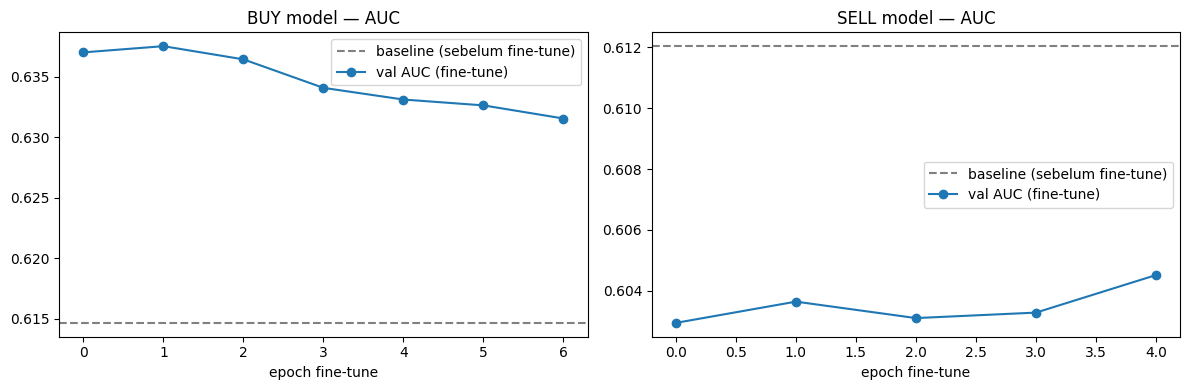

BUY  : AUC baseline=0.6146  -> setelah fine-tune=0.6375
SELL : AUC baseline=0.6120  -> setelah fine-tune=0.6120


In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].axhline(buy_ft_info["baseline"]["auc"], color="gray", linestyle="--", label="baseline (sebelum fine-tune)")
axes[0].plot(buy_ft_info["history"]["val_auc"], label="val AUC (fine-tune)", marker="o")
axes[0].set_title("BUY model — AUC"); axes[0].set_xlabel("epoch fine-tune"); axes[0].legend()

axes[1].axhline(sell_ft_info["baseline"]["auc"], color="gray", linestyle="--", label="baseline (sebelum fine-tune)")
axes[1].plot(sell_ft_info["history"]["val_auc"], label="val AUC (fine-tune)", marker="o")
axes[1].set_title("SELL model — AUC"); axes[1].set_xlabel("epoch fine-tune"); axes[1].legend()

plt.tight_layout()
plt.show()

print(f"BUY  : AUC baseline={buy_ft_info['baseline']['auc']:.4f}  -> setelah fine-tune={buy_ft_info['best_auc']:.4f}")
print(f"SELL : AUC baseline={sell_ft_info['baseline']['auc']:.4f}  -> setelah fine-tune={sell_ft_info['best_auc']:.4f}")


## 13. Kalibrasi Ulang Threshold (opsional, direkomendasikan)
Rezim pasar yang berubah bisa menggeser distribusi probabilitas output model,
jadi threshold precision-target lama (mis. 0.70) belum tentu masih pas. Sel ini
menghitung ulang threshold optimal berdasarkan val set periode fine-tuning
(fungsi `calibrate_threshold` sama seperti di notebook training aslimu).

In [23]:
from sklearn.metrics import precision_recall_curve, fbeta_score

def calibrate_threshold(y_true, y_prob, target_precision=0.70,
                         min_signal_frac=0.01, beta=0.5, label=""):
    """
    Cari threshold optimal dari val set probabilities.
    - target_precision: precision minimum yang mau dijaga
    - min_signal_frac: minimal proporsi sampel yang harus jadi sinyal
                        (mencegah threshold "aman" tapi sinyalnya 0)
    """
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    # precision_recall_curve mengembalikan len(thresholds) = len(precisions) - 1
    precisions, recalls = precisions[:-1], recalls[:-1]

    n_total = len(y_true)
    min_signal = max(int(n_total * min_signal_frac), 1)

    # Kandidat 1: threshold minimum yang precision-nya >= target
    candidates = []
    for p, r, t in zip(precisions, recalls, thresholds):
        n_signal = int(r * y_true.sum())  # perkiraan jumlah sinyal
        if p >= target_precision and n_signal >= min_signal:
            candidates.append((t, p, r, n_signal))

    if candidates:
        # ambil threshold TERENDAH di antara kandidat (paling banyak sinyal
        # sambil tetap penuhi target precision)
        best_t, best_p, best_r, best_n = min(candidates, key=lambda x: x[0])
        reason = f"threshold terendah yang precision>={target_precision}"
    else:
        # fallback: precision target tidak pernah tercapai -> maksimalkan F-beta saja
        fbetas = [(2 if r+p==0 else (1+beta**2)*p*r/(beta**2*p+r+1e-12))
                  for p, r in zip(precisions, recalls)]
        best_idx = int(np.argmax(fbetas))
        best_t = thresholds[best_idx]
        best_p, best_r = precisions[best_idx], recalls[best_idx]
        best_n = int(best_r * y_true.sum())
        reason = f"precision>={target_precision} tidak pernah tercapai -> fallback ke F{beta} maksimal"

    print(f"[{label}] Threshold terkalibrasi = {best_t:.4f}  "
          f"(precision={best_p:.4f}, recall={best_r:.4f}, ~{best_n} sinyal)")
    print(f"          alasan: {reason}")
    return best_t

# ── Jalankan untuk BUY ──────────────────────────────────────
buy_thr = calibrate_threshold(all_targets_buy, all_probs_buy,
                               target_precision=0.70, label="BUY")

# ── Jalankan untuk SELL ─────────────────────────────────────
sell_thr = calibrate_threshold(all_targets_sell, all_probs_sell,
                                target_precision=0.70, label="SELL")

NameError: name 'all_targets_buy' is not defined

In [ ]:
feats_gpu = get_feats_gpu(feats_base)
val_idx_ft_arr = split_info_ft["val_idx"]

val_loader_buy  = GPUBatchIterator(feats_gpu, WINDOW_SIZE, val_idx_ft_arr,
                                    y_buy_tensor[val_idx_ft_arr].numpy(),
                                    batch_size=2048, shuffle=False)
val_loader_sell = GPUBatchIterator(feats_gpu, WINDOW_SIZE, val_idx_ft_arr,
                                    y_sell_tensor[val_idx_ft_arr].numpy(),
                                    batch_size=2048, shuffle=False)

def collect_probs(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits, _ = model(xb)
            probs.append(torch.sigmoid(logits).squeeze(1).cpu().numpy())
            targets.append(yb.cpu().numpy())
    return np.concatenate(probs), np.concatenate(targets)

buy_probs, buy_targets   = collect_probs(buy_model_ft, val_loader_buy)
sell_probs, sell_targets = collect_probs(sell_model_ft, val_loader_sell)

buy_thr_info  = calibrate_threshold(buy_targets, buy_probs, target_precision=0.70, label="BUY")
sell_thr_info = calibrate_threshold(sell_targets, sell_probs, target_precision=0.70, label="SELL")

print("Threshold BUY (baru) :", buy_thr_info)
print("Threshold SELL (baru):", sell_thr_info)


## 14. Catatan Sebelum Pakai Live
- Bandingkan dulu `buy_ft_info` / `sell_ft_info` (AUC & precision baseline vs sesudah
  fine-tune). Kalau fine-tuning **tidak** membaik dibanding baseline, fungsi di atas
  sudah otomatis mengembalikan bobot ke kondisi terbaik yang ditemukan (bisa jadi sama
  dengan model lama) — jadi model `_finetuned.pkl` tidak akan lebih buruk dari model
  lama pada val set ini, tapi tetap perlu dicek manual juga dengan mata.
- Data fine-tuning cuma ~6 bulan (Jan–Jul 2026) — jauh lebih sedikit variasi rezim
  dibanding data training original multi-tahun. Kalau precision/AUC hasil fine-tune
  terlihat jauh lebih rendah dari yang lama, kemungkinan besar karena jumlah sampel
  positif (BUY/SELL) di periode ini memang sedikit, bukan berarti fine-tuningnya salah.
- Sebelum menimpa `buy_model.pkl` / `sell_model.pkl` yang lama, sebaiknya jalankan
  backtest terpisah (bukan cuma val set di notebook ini) memakai model
  `_finetuned.pkl` untuk memastikan performa live tidak turun.
- Kalau ingin fine-tuning ulang di masa depan (mis. tiap bulan), cukup jalankan ulang
  notebook ini dengan `FINE_TUNE_START` digeser maju, dan `PATH_BUY_MODEL` /
  `PATH_SELL_MODEL` diarahkan ke model `_finetuned.pkl` hasil fine-tuning sebelumnya.